# 08 — Convolutional Neural Networks for Biological Image Classification

### Recognizing 102 flower species from photographs

**Learning path:** `Deep Learning / Keras`  
**Notebook:** 08 of 12  
**Level:** Intermediate → advanced  
**Primary tools:** Python, NumPy, Matplotlib, Pillow, SciPy, Keras 3  
**Dataset:** *Oxford 102 Flowers* (8,189 images of 102 flower species commonly found in the United Kingdom)

---

## Learning objectives

By the end of this notebook, you should be able to:

1. Describe an image as a **tensor** (height × width × channels), and explain `uint8`, rescaling, and the channels-last convention.
2. Explain why a fully connected network is a poor choice for images, with parameter counts.
3. Define the **convolution** (cross-correlation) operation for multi-channel images and derive the **output size**, the **parameter count**, and the **number of multiply–accumulate operations** (MACs).
4. Implement convolution and pooling **from scratch in NumPy**, including Keras' `"same"` padding rule, and verify them against Keras.
5. Show that convolution is **translation-equivariant** and that pooling adds a degree of local **translation invariance**.
6. Derive the **backward pass of a convolution**, $\partial L/\partial K$ and $\partial L/\partial X$, and verify it with a numerical gradient check.
7. Compute the **receptive field** of a unit with the recurrence $r_l = r_{l-1} + (k_l - 1)\,j_{l-1}$.
8. Build, train, and compare a multilayer perceptron and two CNNs in Keras on a 102-class problem.
9. **Look inside** a trained network: learned filters, feature maps, and an occlusion-sensitivity analysis.
10. Evaluate an image classifier honestly: top-1/top-5 accuracy, per-class accuracy with confidence intervals, confusion structure, and error analysis.

> **What is new compared with Notebooks 04–07?** The input is no longer a vector of features but a *grid* with spatial structure; the new layers (convolution, pooling) exploit that structure. The mathematics is again derived and **verified numerically** before we use the Keras layers, and the evaluation habits of Notebook 07 (honest splits, intervals, error analysis) carry over.

## 1. The biological problem and the learning task

Identifying a plant species from a photograph is a basic task in botany, ecology, and citizen-science projects (biodiversity monitoring, invasive-species detection, herbarium digitization). A trained expert recognizes a species from a combination of petal shape, colour, arrangement, and context; the task for the network is to learn comparable visual cues from examples.

The *Oxford 102 Flowers* dataset (Nilsback and Zisserman, 2008) contains **8,189 photographs of 102 flower species** that commonly occur in the United Kingdom, with **40 to 258 images per class**. The photographs show large variations in scale, pose, and lighting; some classes vary a lot internally, and several different classes look very similar.

### 1.1 Formal task

Each image is a tensor $x \in \{0, \dots, 255\}^{H \times W \times 3}$ and its label is one of $K = 102$ classes. The network outputs a probability vector $\hat{p}(x) \in \mathbb{R}^{102}$ (softmax), exactly as in Notebook 04, and we train with the cross-entropy loss. The difference lies entirely in **how the network turns pixels into features**.

### 1.2 Why this is a harder problem than the earlier ones

| | Yeast / gene expression | Flowers |
|---|---|---|
| Input | a vector of $8$–$2000$ numeric features | $64 \times 64 \times 3 = 12{,}288$ pixel values (for the size we use) |
| Meaning of an input number | a measured quantity with a fixed identity | a pixel intensity whose meaning depends on its **neighbours** |
| Classes | 5–10 | 102 |
| Samples per class | tens to hundreds | about 40–258 (about 48 per class in our training set) |
| Chance accuracy | 10–20% | 0.98% |

We will work with small images (64 × 64) and small networks so that everything runs on a normal CPU. Accuracy will therefore be moderate; Notebook 09 improves it substantially with **transfer learning** and **data augmentation**.

## 2. Set up the environment

We use Keras 3 with the TensorFlow backend, **Pillow** to read the images, and **SciPy** to read the `.mat` label files. Select the backend before importing Keras.

**Runtime.** Reading the 8,189 images takes a minute or two the first time (the resized images are then cached in a single `.npz` file). Training three networks on a CPU takes roughly 10–25 minutes in total. Set `QUICK_MODE = True` to train for fewer epochs (about 2.5× faster) for a first read.

In [ ]:
# If needed, install the packages in the active Jupyter environment:
# %pip install -U keras tensorflow numpy matplotlib pillow scipy

In [1]:
# Select the backend BEFORE importing Keras.
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

import sys, json, math, time

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from PIL import Image, ImageOps
from scipy.io import loadmat

import keras

SEED = 42
keras.utils.set_random_seed(SEED)

QUICK_MODE = False                      # True: fewer epochs (for a first quick read)
EPOCH_SCALE = 0.4 if QUICK_MODE else 1.0
def epochs_for(n):
    return max(8, int(round(n * EPOCH_SCALE)))

IMAGE_SIZE = 64                         # images are resized to IMAGE_SIZE x IMAGE_SIZE (a new size creates a new cache file)

ARTIFACT_DIR = "artifacts_08"
FIG_DIR = "figures_08"
for folder in (ARTIFACT_DIR, FIG_DIR):
    os.makedirs(folder, exist_ok=True)

print("Python :", sys.version.split()[0])
print("Keras  :", keras.__version__, "| backend:", keras.backend.backend())
print("NumPy  :", np.__version__, "| Pillow:", Image.__version__)
print("Image size:", IMAGE_SIZE, "| quick mode:", QUICK_MODE)

Python : 3.11.0
Keras  : 3.15.1 | backend: tensorflow
NumPy  : 2.4.6 | Pillow: 12.3.0
Image size: 64 | quick mode: False


## 3. Visual style

The same style as before, with a restrained palette and figures exported to a folder (`figures_08`).

In [4]:
COLORS = {"blue": "#2563EB", "orange": "#F59E0B", "green": "#10B981", "red": "#EF4444",
          "purple": "#8B5CF6", "gray": "#6B7280", "dark": "#111827", "light": "#E5E7EB",
          "teal": "#0D9488", "pink": "#DB2777"}
MODEL_COLORS = {"MLP on pixels": COLORS["gray"], "CNN": COLORS["blue"], "CNN + BatchNorm + Dropout": COLORS["orange"]}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": COLORS["gray"], "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": COLORS["light"], "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelsize": 10,
    "axes.labelcolor": COLORS["dark"], "xtick.color": COLORS["dark"], "ytick.color": COLORS["dark"],
    "font.size": 10, "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 2.0,
})

SAVE_FIGURES = True
def finish(fig, name, pad=1.0):
    fig.tight_layout(pad=pad)
    if SAVE_FIGURES:
        fig.savefig(os.path.join(FIG_DIR, f"{name}.png"), bbox_inches="tight")
    plt.show()
    plt.close(fig)

## 4. The dataset

You downloaded three items from the Oxford VGG page (<https://www.robots.ox.ac.uk/~vgg/data/flowers/102/>) into `data/flowers102/`:

| Item | Content |
|---|---|
| `jpg/` (from `102flowers.tgz`) | the 8,189 images, named `image_00001.jpg` … `image_08189.jpg` |
| `imagelabels.mat` | the class (1–102) of each image |
| `setid.mat` | the **official** train / validation / test split (`trnid`, `valid`, `tstid`) |

The class *names* are not part of these files, so we refer to the classes by their number (0–101 in the code). The images have different sizes and aspect ratios. We make them uniform by **resizing the shorter side to 64 pixels and cropping the centre** (this keeps the aspect ratio of the content but can cut off the edges of elongated flowers — a limitation to keep in mind), and cache the result.

In [6]:
FLOWERS_DIR = os.path.join("data", "flowers102")
CACHE_PATH = os.path.join(FLOWERS_DIR, f"flowers102_{IMAGE_SIZE}px.npz")
RESAMPLE = getattr(Image, "Resampling", Image).LANCZOS

def image_path(i):                       # i is a 0-based image index
    return os.path.join(FLOWERS_DIR, "jpg", f"image_{i + 1:05d}.jpg")

def load_image_file(i, size):
    """Load one image, resize the shorter side to `size`, and crop the centre."""
    with Image.open(image_path(i)) as im:
        return np.asarray(ImageOps.fit(im.convert("RGB"), (size, size), method=RESAMPLE))

def load_flowers(size=IMAGE_SIZE):
    if os.path.exists(CACHE_PATH):
        with np.load(CACHE_PATH) as f:
            return f["images"], f["labels"], {k: f[k] for k in ("trnid", "valid", "tstid")}
    required = [os.path.join(FLOWERS_DIR, "imagelabels.mat"), os.path.join(FLOWERS_DIR, "setid.mat"), os.path.join(FLOWERS_DIR, "jpg")]
    missing = [p for p in required if not os.path.exists(p)]
    if missing:
        raise RuntimeError(f"Missing: {missing}. Download 102flowers.tgz, imagelabels.mat and setid.mat from "
                           "https://www.robots.ox.ac.uk/~vgg/data/flowers/102/ , place the .mat files in "
                           f"'{FLOWERS_DIR}' and extract the archive there (it creates the 'jpg' folder).")
    labels = loadmat(required[0], squeeze_me=True)["labels"].astype(np.int64) - 1          # 0..101
    setid = loadmat(required[1], squeeze_me=True)
    official = {k: setid[k].astype(np.int64) - 1 for k in ("trnid", "valid", "tstid")}      # 0-based image indices
    images = np.empty((len(labels), size, size, 3), dtype=np.uint8)
    t0 = time.time()
    for i in range(len(labels)):
        images[i] = load_image_file(i, size)
        if (i + 1) % 1000 == 0:
            print(f"  {i + 1} / {len(labels)} images ({time.time() - t0:.0f} s)")
    np.savez_compressed(CACHE_PATH, images=images, labels=labels, **official)
    return images, labels, official

images_all, labels_all, official_split = load_flowers()
N_CLASSES = 102
print("Images:", images_all.shape, images_all.dtype, "| labels:", labels_all.shape)

  1000 / 8189 images (9 s)
  2000 / 8189 images (18 s)
  3000 / 8189 images (27 s)
  4000 / 8189 images (36 s)
  5000 / 8189 images (45 s)
  6000 / 8189 images (54 s)
  7000 / 8189 images (63 s)
  8000 / 8189 images (72 s)
Images: (8189, 64, 64, 3) uint8 | labels: (8189,)


In [7]:
assert images_all.shape[0] == 8189 and images_all.shape[1:] == (IMAGE_SIZE, IMAGE_SIZE, 3)
assert labels_all.min() == 0 and labels_all.max() == N_CLASSES - 1 and len(np.unique(labels_all)) == N_CLASSES

class_counts = np.bincount(labels_all, minlength=N_CLASSES)
official_sizes = {k: len(v) for k, v in official_split.items()}
all_official = np.concatenate(list(official_split.values()))
assert len(np.unique(all_official)) == len(all_official) == len(labels_all), "the official split should partition the images"

print(f"Images per class: min {class_counts.min()}, median {int(np.median(class_counts))}, max {class_counts.max()}")
print("Official split sizes (train / validation / test):", official_sizes["trnid"], "/", official_sizes["valid"], "/", official_sizes["tstid"])
print("Pixel value range:", int(images_all.min()), "to", int(images_all.max()))

Images per class: min 40, median 66, max 258
Official split sizes (train / validation / test): 1020 / 1020 / 6149
Pixel value range: 0 to 255


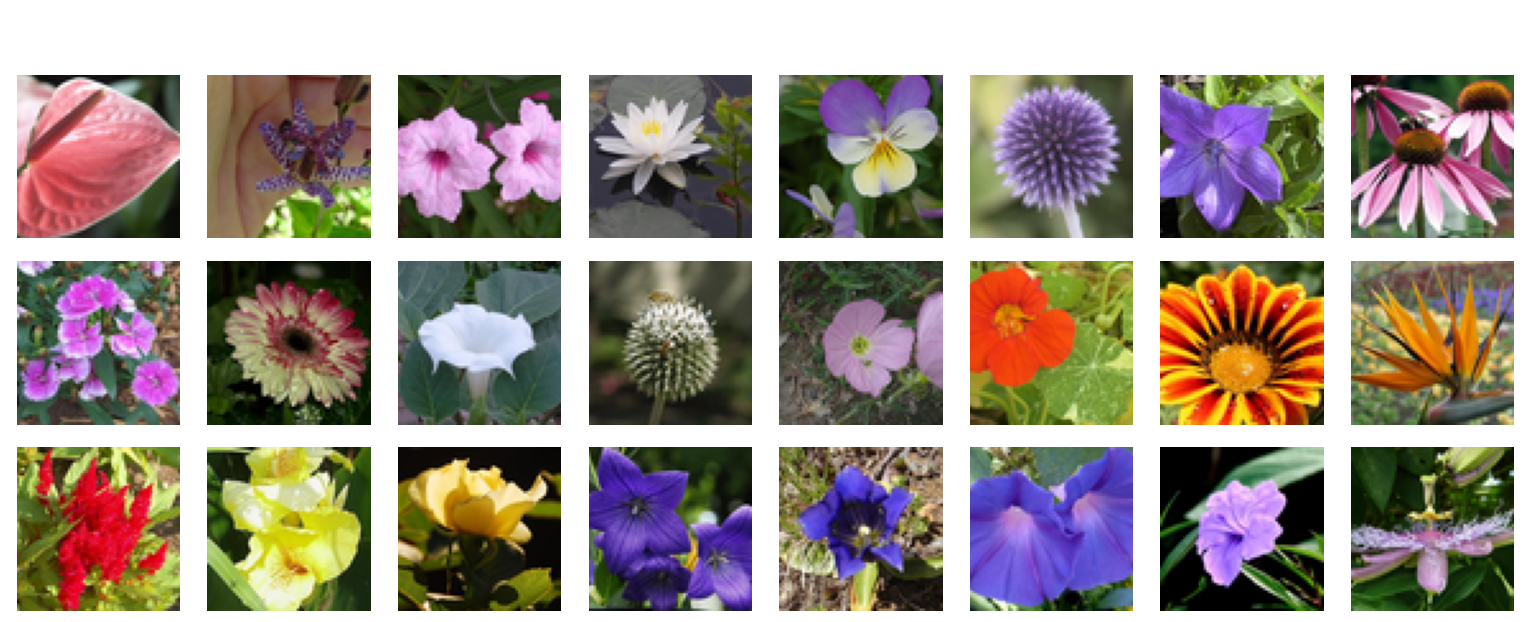

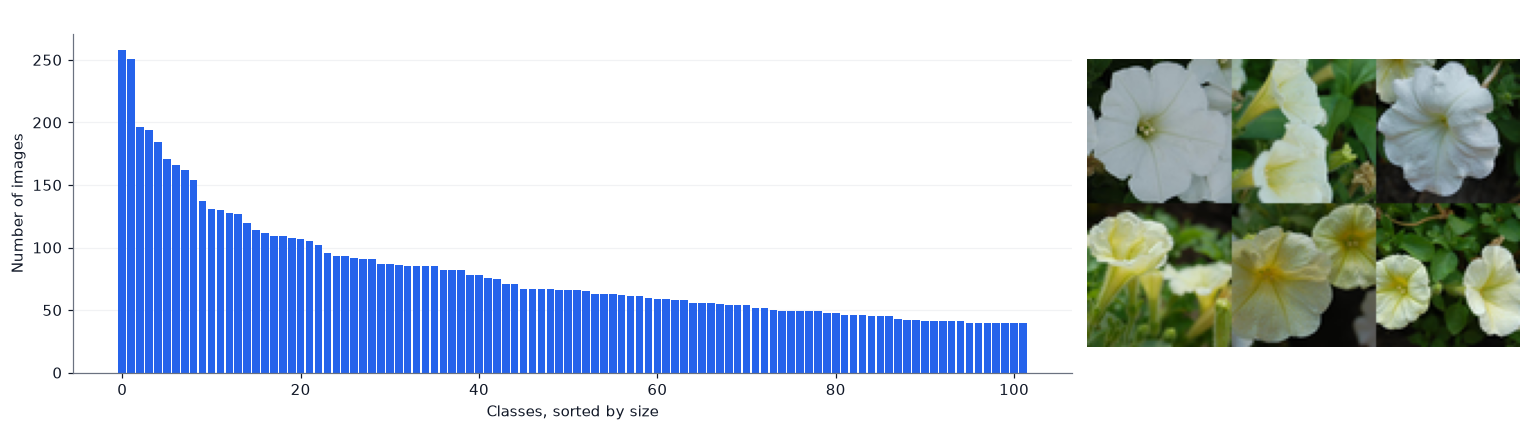

In [8]:
rng = np.random.default_rng(1)
sample = rng.choice(len(images_all), size=24, replace=False)

fig, axes = plt.subplots(3, 8, figsize=(14, 5.6))
for ax, i in zip(axes.ravel(), sample):
    ax.imshow(images_all[i]); ax.set_title(f"class {labels_all[i]}", fontsize=9); ax.axis("off")
fig.suptitle(f"A random sample of the data (cached at {IMAGE_SIZE} \u00d7 {IMAGE_SIZE} pixels)", fontsize=13, fontweight="bold", x=0.01, ha="left", y=1.0)
finish(fig, "01_sample_images")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.0), gridspec_kw={"width_ratios": [3, 1.3]})
order = np.argsort(-class_counts)
axes[0].bar(np.arange(N_CLASSES), class_counts[order], color=COLORS["blue"], width=0.85)
axes[0].set_xlabel("Classes, sorted by size"); axes[0].set_ylabel("Number of images"); axes[0].set_title("Class sizes (the dataset is moderately imbalanced)"); axes[0].grid(axis="x", visible=False)
# Two images of the SAME class to show intra-class variation:
big_class = int(np.argmax(class_counts)); idx_c = np.flatnonzero(labels_all == big_class)[:6]
axes[1].imshow(np.vstack([np.hstack([images_all[i] for i in idx_c[:3]]), np.hstack([images_all[i] for i in idx_c[3:6]])])); axes[1].axis("off")
axes[1].set_title(f"Six images of class {big_class}", fontsize=10)
finish(fig, "02_class_sizes")

### 4.1 Which split should we use?

The **official** split has only about **1,020 images for training**, 1,020 for validation, and about **6,150 for testing**. It was designed for methods that learn from very few examples (10 per class). For a small CNN trained from scratch that is a very small training set, and it makes the test set much larger than needed.

We therefore use **our own stratified split of all 8,189 images: 60% training, 20% validation, 20% test** (about 48, 16, and 16 images per class on average). The validation set is used for early stopping and for model selection; the test set is used **once** at the end (Notebook 07). If you want to compare with published results, use the official split and say so.

**A caution about leakage.** Photographs of the *same plant* (or of flowers from the same field on the same day) can be very similar. The dataset has no identifier that would let us split by plant, so near-duplicate images may fall into different partitions and make the test accuracy slightly optimistic. This is the image-data version of the homologous-protein and same-patient problems of earlier notebooks.

In [9]:
def stratified_split_indices(labels, val_fraction=0.2, test_fraction=0.2, seed=SEED):
    """Train/validation/test indices; every class appears in every partition."""
    split_rng = np.random.default_rng(seed)
    tr, va, te = [], [], []
    for c in np.unique(labels):
        idx = split_rng.permutation(np.flatnonzero(labels == c))
        n_val = max(1, int(round(val_fraction * len(idx)))); n_test = max(1, int(round(test_fraction * len(idx))))
        va.append(idx[:n_val]); te.append(idx[n_val:n_val + n_test]); tr.append(idx[n_val + n_test:])
    return [split_rng.permutation(np.concatenate(p)) for p in (tr, va, te)]

tr_idx, va_idx, te_idx = stratified_split_indices(labels_all)
assert len(set(tr_idx) | set(va_idx) | set(te_idx)) == len(labels_all)

X_train, y_train = images_all[tr_idx], labels_all[tr_idx].astype("int32")
X_val, y_val = images_all[va_idx], labels_all[va_idx].astype("int32")
X_test, y_test = images_all[te_idx], labels_all[te_idx].astype("int32")

print("Training / validation / test images:", len(y_train), "/", len(y_val), "/", len(y_test))
print("Images per class in the test set: min", np.bincount(y_test).min(), "| median", int(np.median(np.bincount(y_test))), "| max", np.bincount(y_test).max())
print("Chance accuracy: top-1 =", round(1 / N_CLASSES, 4), "| top-5 =", round(5 / N_CLASSES, 4))

Training / validation / test images: 4923 / 1633 / 1633
Images per class in the test set: min 8 | median 13 | max 52
Chance accuracy: top-1 = 0.0098 | top-5 = 0.049


# Part I — The mathematics of convolutional networks

## 5. Images as tensors

A colour image is a 3-dimensional array $X \in \mathbb{R}^{H \times W \times C}$: height, width, and $C = 3$ **channels** (red, green, blue). Keras uses the **channels-last** convention, and a *batch* of images has shape $(N, H, W, C)$. Files store each value as an unsigned 8-bit integer (`uint8`, 0–255). Neural networks work with floating-point numbers of moderate size, so the first layer of our models is a `Rescaling(1/255)` layer that maps the values to $[0, 1]$. Doing this **inside the model** means that raw images can be fed at prediction time, and nobody has to remember the preprocessing.

Memory for our data: $64 \times 64 \times 3 = 12{,}288$ bytes per image as `uint8`, but 4 times more as `float32`. Keeping the dataset in `uint8` and converting batch by batch inside the model saves memory.

One image: (64, 64, 3) uint8 | minimum 5 | maximum 255
Pixel at row 10, column 20 (R, G, B): [250 161 175]

Top-left 3 x 3 patch of the red channel:
 [[213 210 203]
 [221 223 224]
 [213 215 220]]

A batch of 32 images: (32, 64, 64, 3) -> (N, H, W, C)


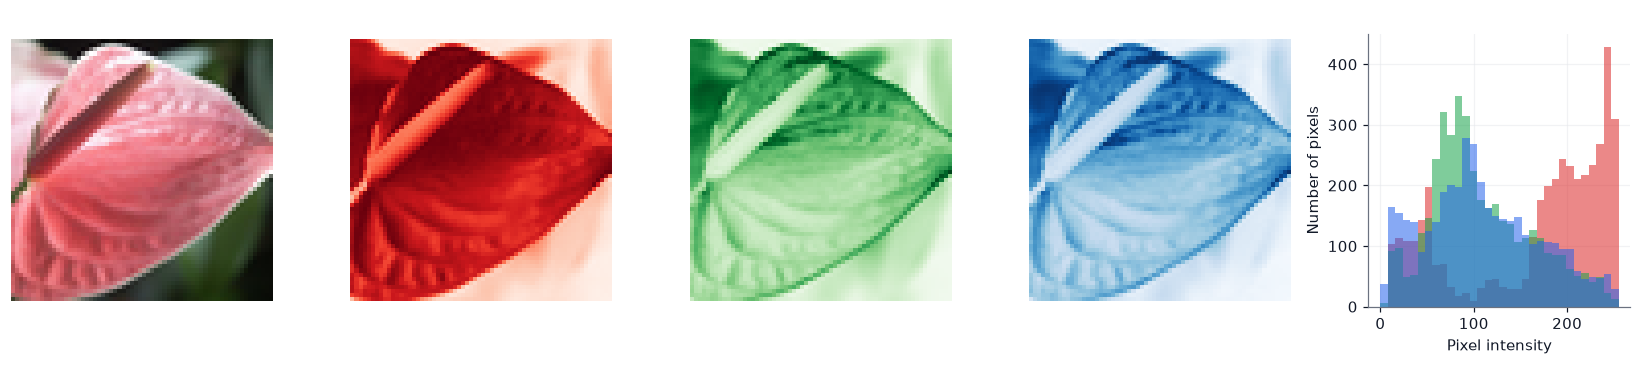

In [10]:
example = images_all[sample[0]]
print("One image:", example.shape, example.dtype, "| minimum", example.min(), "| maximum", example.max())
print("Pixel at row 10, column 20 (R, G, B):", example[10, 20])
print("\nTop-left 3 x 3 patch of the red channel:\n", example[:3, :3, 0])
print("\nA batch of 32 images:", images_all[:32].shape, "-> (N, H, W, C)")

fig, axes = plt.subplots(1, 5, figsize=(15, 3.4))
axes[0].imshow(example); axes[0].set_title("RGB image")
for ax, (c, name, cmap) in zip(axes[1:4], [(0, "Red channel", "Reds"), (1, "Green channel", "Greens"), (2, "Blue channel", "Blues")]):
    ax.imshow(example[:, :, c], cmap=cmap, vmin=0, vmax=255); ax.set_title(name)
for ax in axes[:4]:
    ax.axis("off")
for c, color in enumerate(["#DC2626", "#16A34A", "#2563EB"]):
    axes[4].hist(example[:, :, c].ravel(), bins=32, range=(0, 255), color=color, alpha=0.55)
axes[4].set_xlabel("Pixel intensity"); axes[4].set_ylabel("Number of pixels"); axes[4].set_title("Intensity histograms")
finish(fig, "03_image_tensor")

## 6. Why not a fully connected network?

A fully connected (Dense) layer connects every input value to every unit. For an $S \times S \times 3$ image and a first hidden layer of $U$ units, it has $(3S^2 + 1)\,U$ parameters. Besides being huge, it has two conceptual problems:

1. **No built-in notion of neighbourhood.** Shuffling the pixels with a fixed permutation would not change what a Dense network can learn: it treats the image as an unordered bag of numbers.
2. **No translation equivariance.** A flower that moves a few pixels to the right activates a completely different set of weights, so the network must learn to recognize "the same petal" separately at every position.

Convolutional layers fix both with **local connectivity** (each output depends on a small neighbourhood) and **parameter sharing** (the same small filter is applied at every position).

In [11]:
print(f"{'image size':>12} | {'inputs':>9} | {'first Dense(256) parameters':>28} | {'Conv2D(32, 3x3) parameters':>26}")
for S in (32, 64, 128, 224):
    print(f"{S:>5} x {S:<5} | {3 * S * S:>9,} | {(3 * S * S + 1) * 256:>28,} | {(3 * 3 * 3 + 1) * 32:>26,}")
print("\nA 3x3 convolution with 32 filters has the same 896 parameters for every image size: the number of parameters does not depend on the image size.")

  image size |    inputs |  first Dense(256) parameters | Conv2D(32, 3x3) parameters
   32 x 32    |     3,072 |                      786,688 |                        896
   64 x 64    |    12,288 |                    3,145,984 |                        896
  128 x 128   |    49,152 |                   12,583,168 |                        896
  224 x 224   |   150,528 |                   38,535,424 |                        896

A 3x3 convolution with 32 filters has the same 896 parameters for every image size: the number of parameters does not depend on the image size.


## 7. The convolution operation

### 7.1 Definition

Deep-learning libraries compute a **cross-correlation** (they do not flip the kernel; since the kernel is learned, flipping would make no difference to what the network can represent) and call it convolution. For an input $X \in \mathbb{R}^{H \times W \times C_{in}}$, a bank of $C_{out}$ filters $K \in \mathbb{R}^{k_h \times k_w \times C_{in} \times C_{out}}$, biases $b \in \mathbb{R}^{C_{out}}$, **stride** $s$, and zero padding $p$:

$$
Y_{i,j,f} \;=\; b_f \;+\; \sum_{m=0}^{k_h-1}\sum_{n=0}^{k_w-1}\sum_{c=1}^{C_{in}} \tilde{X}_{\,s i + m,\; s j + n,\; c}\;K_{m,n,c,f},
$$

where $\tilde{X}$ is $X$ padded with zeros. Each output value is a **weighted sum over a small window** of the input (all channels), exactly like one unit of a Dense layer applied to that window; the *same* weights are used at every position $(i, j)$, and each filter $f$ produces one output channel, a **feature map**.

### 7.2 Output size, parameters, and cost

With input size $n$ (height or width), kernel size $k$, stride $s$, and total padding $2p$:

$$
n_{out} = \Big\lfloor \frac{n + 2p - k}{s} \Big\rfloor + 1 .
$$

Keras offers two padding modes: `"valid"` (no padding, so $n_{out} = \lfloor (n-k)/s \rfloor + 1$) and `"same"` (zero padding such that $n_{out} = \lceil n/s \rceil$; with stride 1 the output has the input's size). For `"same"`, the total padding is $\max\big((n_{out}-1)s + k - n,\, 0\big)$; if it is odd, the extra zero goes **after** (bottom/right) the image.

$$
\#\text{parameters} = (k_h k_w C_{in} + 1)\, C_{out}, \qquad
\#\text{MACs} = H_{out}\, W_{out}\, k_h k_w C_{in}\, C_{out} .
$$

(One multiply–accumulate is one multiplication plus one addition; the number of floating-point operations is about twice the MACs.) The parameter count does **not** depend on the image size, but the computation does.

### 7.3 A worked example

A $5 \times 5$ input, a $3 \times 3$ vertical-edge kernel, stride 1, no padding: the output is $3 \times 3$. Each output value is the sum of the 9 elementwise products of the kernel and a $3 \times 3$ window.

In [12]:
def conv_output_size(n, k, s, padding):
    return (n - k) // s + 1 if padding == "valid" else -(-n // s)

def pad_amounts(n, k, s, padding):
    """Zero padding (before, after) along one axis, following the TensorFlow/Keras convention for 'same'."""
    if padding == "valid":
        return 0, 0
    out = -(-n // s)
    total = max((out - 1) * s + k - n, 0)
    return total // 2, total - total // 2

def conv2d_numpy(x, kernel, bias, stride=1, padding="valid"):
    """Cross-correlation of a batch x (N,H,W,Cin) with kernel (kh,kw,Cin,Cout) and bias (Cout,)."""
    N, H, W, _ = x.shape
    kh, kw, _, F = kernel.shape
    pt, pb = pad_amounts(H, kh, stride, padding); pl, pr = pad_amounts(W, kw, stride, padding)
    xp = np.pad(x, ((0, 0), (pt, pb), (pl, pr), (0, 0)))
    Ho, Wo = (xp.shape[1] - kh) // stride + 1, (xp.shape[2] - kw) // stride + 1
    out = np.zeros((N, Ho, Wo, F))
    for m in range(kh):
        for n_ in range(kw):
            window = xp[:, m:m + stride * Ho:stride, n_:n_ + stride * Wo:stride, :]      # (N, Ho, Wo, Cin)
            out += window @ kernel[m, n_]                                                  # (Cin) x (Cin, F)
    return out + bias

def conv2d_naive(x, kernel, bias):
    """Direct implementation of the definition (valid padding, stride 1) with explicit loops, for checking."""
    N, H, W, C = x.shape; kh, kw, _, F = kernel.shape
    out = np.zeros((N, H - kh + 1, W - kw + 1, F))
    for b_ in range(N):
        for i in range(H - kh + 1):
            for j in range(W - kw + 1):
                for f in range(F):
                    out[b_, i, j, f] = bias[f] + np.sum(x[b_, i:i + kh, j:j + kw, :] * kernel[:, :, :, f])
    return out

# --- The worked example of the text
X5 = np.array([[1, 2, 0, 1, 3], [0, 1, 2, 3, 1], [1, 0, 1, 2, 2], [2, 1, 0, 1, 0], [1, 3, 1, 0, 2]], dtype=float)
K3 = np.array([[1, 0, -1], [1, 0, -1], [1, 0, -1]], dtype=float)
Y3 = conv2d_numpy(X5[None, :, :, None], K3[:, :, None, None], np.zeros(1))[0, :, :, 0]
window = X5[0:3, 1:4]
print("Output of the worked example:\n", Y3)
print("\nY[0, 1] = sum(window * kernel) with window =\n", window, "\n=", float(np.sum(window * K3)))
assert np.isclose(Y3[0, 1], np.sum(window * K3))

# --- The vectorized implementation agrees with the definition
rg = np.random.default_rng(0)
x_t, k_t, b_t = rg.normal(size=(2, 7, 6, 3)), rg.normal(size=(3, 2, 3, 4)), rg.normal(size=4)
print("\nvectorized vs naive loops, maximum difference:", np.abs(conv2d_numpy(x_t, k_t, b_t) - conv2d_naive(x_t, k_t, b_t)).max())

Output of the worked example:
 [[-1. -3. -3.]
 [ 0. -4.  0.]
 [ 2.  1. -2.]]

Y[0, 1] = sum(window * kernel) with window =
 [[2. 0. 1.]
 [1. 2. 3.]
 [0. 1. 2.]] 
= -3.0

vectorized vs naive loops, maximum difference: 3.552713678800501e-15


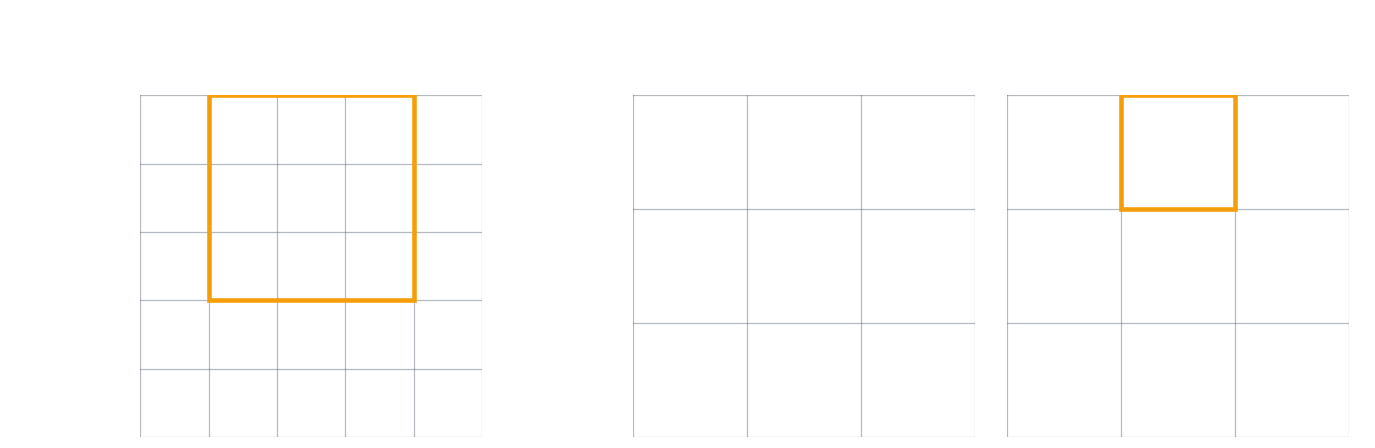

In [13]:
def draw_matrix(ax, M, title, window=None, cell=None, color=COLORS["orange"]):
    ax.imshow(np.zeros(M.shape), cmap="Greys", vmin=0, vmax=10, alpha=0.04)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M[i, j]:g}", ha="center", va="center", fontsize=12)
    ax.set_xticks(np.arange(-.5, M.shape[1], 1), minor=True); ax.set_yticks(np.arange(-.5, M.shape[0], 1), minor=True)
    ax.grid(which="minor", color=COLORS["gray"], linewidth=0.8); ax.grid(which="major", visible=False)
    ax.tick_params(which="both", length=0); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title)
    for s in ax.spines.values():
        s.set_visible(False)
    if window is not None:
        (r0, c0), (h, w) = window
        ax.add_patch(plt.Rectangle((c0 - .5, r0 - .5), w, h, fill=False, edgecolor=color, linewidth=3))
    if cell is not None:
        ax.add_patch(plt.Rectangle((cell[1] - .5, cell[0] - .5), 1, 1, fill=False, edgecolor=color, linewidth=3))

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.9), gridspec_kw={"width_ratios": [5, 3, 3]})
draw_matrix(axes[0], X5, "Input X (5 \u00d7 5), highlighted window", window=((0, 1), (3, 3)))
draw_matrix(axes[1], K3, "Kernel K (3 \u00d7 3)", color=COLORS["blue"])
draw_matrix(axes[2], Y3, "Output Y (3 \u00d7 3), highlighted value", cell=(0, 1))
fig.suptitle("Each output value is the sum of the elementwise products of the kernel and one window of the input", fontsize=12, fontweight="bold", x=0.01, ha="left", y=1.03)
finish(fig, "04_convolution_example")

### 7.4 Verifying against Keras

We check three things with real Keras layers: the output **shape** (the formula above), the **values** (our NumPy implementation), and the `"same"` **padding rule**, including the case in which the total padding is odd and the extra zero goes after the image ($n = 8$, $k = 3$, $s = 2$). We load random weights into the Keras layer with `set_weights`; the Keras kernel layout is $(k_h, k_w, C_{in}, C_{out})$.

In [14]:
def check_against_keras(n, k, s, padding, c_in=3, c_out=4, seed=0):
    r = np.random.default_rng(seed)
    x = r.normal(size=(2, n, n, c_in)).astype("float32")
    layer = keras.layers.Conv2D(c_out, k, strides=s, padding=padding)
    layer(x)                                                                    # builds the layer (creates the weights)
    K_ = r.normal(size=(k, k, c_in, c_out)).astype("float32"); b_ = r.normal(size=(c_out,)).astype("float32")
    layer.set_weights([K_, b_])
    out_keras = keras.ops.convert_to_numpy(layer(x))
    out_ours = conv2d_numpy(x.astype(float), K_.astype(float), b_.astype(float), s, padding)
    predicted = conv_output_size(n, k, s, padding)
    return out_keras.shape[1], predicted, float(np.abs(out_keras - out_ours).max())

print(f"{'n':>3} {'k':>2} {'s':>2} {'padding':>8} | {'Keras output size':>17} | {'formula':>7} | {'max |difference|':>16}")
for n, k, s, padding in [(9, 3, 1, "valid"), (9, 3, 1, "same"), (9, 3, 2, "valid"), (9, 3, 2, "same"), (8, 3, 2, "same"), (9, 5, 2, "same")]:
    size_keras, size_formula, diff = check_against_keras(n, k, s, padding)
    print(f"{n:>3} {k:>2} {s:>2} {padding:>8} | {size_keras:>17} | {size_formula:>7} | {diff:>16.2e}")
    assert size_keras == size_formula and diff < 1e-4
print("\nOutput sizes and values agree with Keras (including the asymmetric 'same' padding for n = 8).")

  n  k  s  padding | Keras output size | formula | max |difference|
  9  3  1    valid |                 7 |       7 |         2.36e-06
  9  3  1     same |                 9 |       9 |         2.36e-06
  9  3  2    valid |                 4 |       4 |         2.36e-06
  9  3  2     same |                 5 |       5 |         8.97e-07
  8  3  2     same |                 4 |       4 |         1.82e-06
  9  5  2     same |                 5 |       5 |         2.79e-06

Output sizes and values agree with Keras (including the asymmetric 'same' padding for n = 8).


### 7.5 What do filters do? Hand-made filters on a flower

Before any learning, we can see what a convolution computes by applying classic filters to a flower photograph (converted to grey levels):

- **Sobel filters** respond to intensity changes (edges): $K_x$ to horizontal changes (vertical edges), $K_y$ to vertical changes. The gradient magnitude is $\sqrt{Y_x^2 + Y_y^2}$.
- A **box blur** averages a neighbourhood (a low-pass filter).

A CNN **learns** a whole bank of such filters, starting with edge- and colour-like detectors in the first layer and combining them into more and more complex patterns in the later layers.

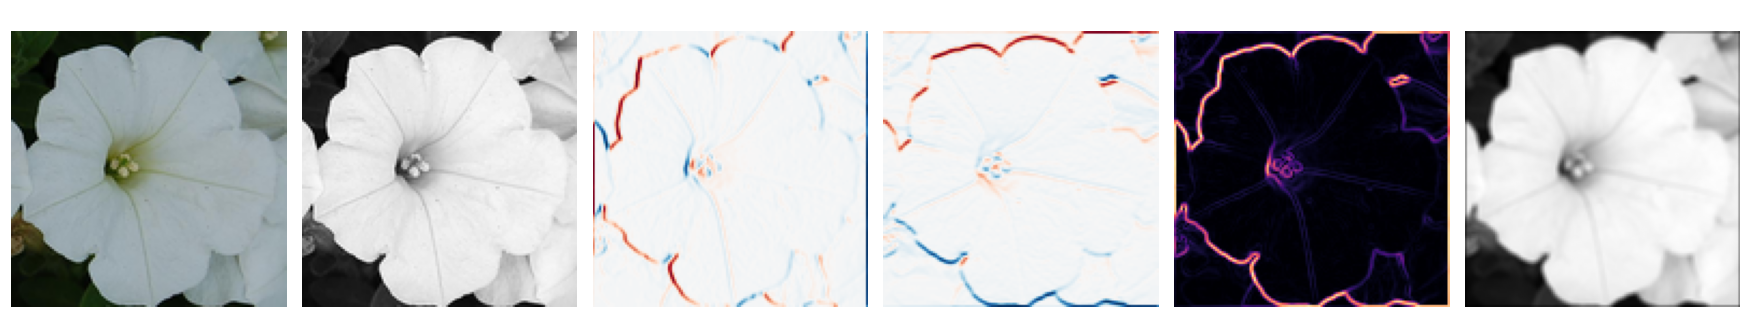

In [15]:
demo_index = np.flatnonzero(labels_all == big_class)[0]
demo_rgb = load_image_file(demo_index, 128).astype(float) / 255
demo_gray = (0.299 * demo_rgb[:, :, 0] + 0.587 * demo_rgb[:, :, 1] + 0.114 * demo_rgb[:, :, 2])[None, :, :, None]

sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=float)
sobel_y = sobel_x.T
box_blur = np.ones((3, 3)) / 9.0
apply_filter = lambda kernel: conv2d_numpy(demo_gray, kernel[:, :, None, None], np.zeros(1), 1, "same")[0, :, :, 0]
gx, gy, blurred = apply_filter(sobel_x), apply_filter(sobel_y), apply_filter(box_blur)

fig, axes = plt.subplots(1, 6, figsize=(16, 3.2))
panels = [(demo_rgb, None, "Original"), (demo_gray[0, :, :, 0], "gray", "Grey levels"), (gx, "RdBu_r", "Sobel $K_x$ (vertical edges)"),
          (gy, "RdBu_r", "Sobel $K_y$ (horizontal edges)"), (np.sqrt(gx**2 + gy**2), "magma", "Gradient magnitude"), (blurred, "gray", "Box blur 3\u00d73")]
for ax, (img, cmap, title) in zip(axes, panels):
    ax.imshow(img, cmap=cmap); ax.set_title(title, fontsize=10); ax.axis("off")
finish(fig, "05_handmade_filters")

### 7.6 Translation equivariance

Let $T_\Delta$ be the operation that shifts an image by $\Delta = (\Delta_i, \Delta_j)$ pixels. Convolution commutes with shifts (away from the borders):

$$
\operatorname{conv}\big(T_\Delta X\big) = T_\Delta\,\operatorname{conv}(X) .
$$

*Proof sketch:* $Y_{i,j} = \sum_{m,n} X_{i+m,\,j+n}K_{m,n}$; shifting $X$ by $\Delta$ gives $X'_{a,b} = X_{a-\Delta_i,\,b-\Delta_j}$ and so $Y'_{i,j} = \sum_{m,n} X_{i-\Delta_i+m,\,j-\Delta_j+n}K_{m,n} = Y_{i-\Delta_i,\,j-\Delta_j}$.

This property is called **equivariance** (the output shifts together with the input). It is what makes parameter sharing sensible: a filter that detects a petal edge at one position detects it anywhere. We check it numerically.

In [16]:
rg = np.random.default_rng(3)
img = rg.normal(size=(1, 32, 32, 1)); ker = rg.normal(size=(3, 3, 1, 1))
shift_i, shift_j = 3, 5
y_plain = conv2d_numpy(img, ker, np.zeros(1))[0, :, :, 0]
y_shifted_input = conv2d_numpy(np.roll(img, (shift_i, shift_j), axis=(1, 2)), ker, np.zeros(1))[0, :, :, 0]

# Away from the wrap-around region, conv(shift(x)) equals shift(conv(x)):
diff = np.abs(y_shifted_input[shift_i:, shift_j:] - y_plain[:-shift_i, :-shift_j]).max()
print(f"Maximum difference between conv(shift(x)) and shift(conv(x)) in the interior: {diff:.2e}")
assert diff < 1e-12

Maximum difference between conv(shift(x)) and shift(conv(x)) in the interior: 0.00e+00


## 8. Pooling

A **pooling** layer summarizes each small window of every feature map with one number, shrinking the spatial size:

$$
\text{max pooling: } Y_{i,j,c} = \max_{0 \le m,n < p} X_{s i + m,\; s j + n,\; c}, \qquad
\text{average pooling: } Y_{i,j,c} = \frac{1}{p^2}\sum_{m,n} X_{s i + m,\; s j + n,\; c},
$$

with window size $p$ and stride $s$ (Keras default: $s = p$, no padding), so $n_{out} = \lfloor (n - p)/s \rfloor + 1$; for $p = s = 2$ this is $\lfloor n/2 \rfloor$ (an odd last row or column is dropped). Pooling has **no parameters** and is applied to each channel separately.

Effects of pooling:

1. It **reduces computation and memory** (here by a factor of 4 per layer).
2. It increases the **receptive field** of later layers (Section 10).
3. Max pooling adds a small amount of **local translation invariance**: if the strongest response moves by one pixel inside its window, the pooled output does not change. This is only approximate and only for shifts smaller than the window.

**Global average pooling (GAP)** averages each whole feature map into a single number, so a stack of $C$ feature maps becomes a vector of length $C$. Compared with `Flatten` followed by a Dense layer, it removes almost all parameters: for $8 \times 8 \times 128$ feature maps and 102 classes, `Flatten` + `Dense` needs $8192 \cdot 102 + 102 = 835{,}686$ parameters, while GAP + `Dense` needs $128 \cdot 102 + 102 = 13{,}158$.

In [17]:
def pool2d_numpy(x, pool=2, stride=None, mode="max"):
    stride = stride or pool
    N, H, W, C = x.shape
    Ho, Wo = (H - pool) // stride + 1, (W - pool) // stride + 1
    windows = np.stack([x[:, m:m + stride * Ho:stride, n_:n_ + stride * Wo:stride, :] for m in range(pool) for n_ in range(pool)], axis=0)
    return windows.max(axis=0) if mode == "max" else windows.mean(axis=0)

rg = np.random.default_rng(4)
x_p = rg.normal(size=(2, 9, 9, 3)).astype("float32")                           # odd size on purpose
for name, layer, mode in [("MaxPooling2D(2)", keras.layers.MaxPooling2D(2), "max"), ("AveragePooling2D(2)", keras.layers.AveragePooling2D(2), "mean")]:
    out_keras = keras.ops.convert_to_numpy(layer(x_p)); out_ours = pool2d_numpy(x_p.astype(float), 2, mode=mode)
    print(f"{name:20s} Keras output shape {out_keras.shape} | ours {out_ours.shape} | max difference {np.abs(out_keras - out_ours).max():.2e}")
    assert out_keras.shape == out_ours.shape and np.abs(out_keras - out_ours).max() < 1e-5

# Global average pooling = the mean over the two spatial axes.
gap = keras.ops.convert_to_numpy(keras.layers.GlobalAveragePooling2D()(x_p))
print("GlobalAveragePooling2D:", gap.shape, "| equals the spatial mean:", np.allclose(gap, x_p.mean(axis=(1, 2)), atol=1e-6))

MaxPooling2D(2)      Keras output shape (2, 4, 4, 3) | ours (2, 4, 4, 3) | max difference 0.00e+00
AveragePooling2D(2)  Keras output shape (2, 4, 4, 3) | ours (2, 4, 4, 3) | max difference 8.94e-08
GlobalAveragePooling2D: (2, 3) | equals the spatial mean: True


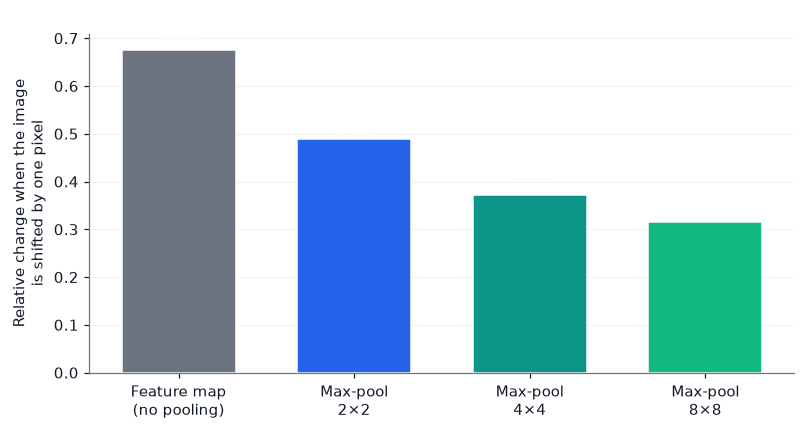

In [18]:
# Local translation invariance: shift the image by ONE pixel and measure how much the representation changes.
gray2d = demo_gray                                                                  # (1, 128, 128, 1)
edge = lambda a: np.abs(conv2d_numpy(a, sobel_x[:, :, None, None], np.zeros(1), 1, "same"))
shifted = np.roll(gray2d, 1, axis=2)

fmap, fmap_shifted = edge(gray2d), edge(shifted)
rel_change = lambda a, b: float(np.linalg.norm(a - b) / np.linalg.norm(a))
change_conv = rel_change(fmap, fmap_shifted)
change_pool2 = rel_change(pool2d_numpy(fmap, 2), pool2d_numpy(fmap_shifted, 2))
change_pool4 = rel_change(pool2d_numpy(fmap, 4), pool2d_numpy(fmap_shifted, 4))
change_pool8 = rel_change(pool2d_numpy(fmap, 8), pool2d_numpy(fmap_shifted, 8))

fig, ax = plt.subplots(figsize=(7.4, 4.0))
labels_bar = ["Feature map\n(no pooling)", "Max-pool\n2\u00d72", "Max-pool\n4\u00d74", "Max-pool\n8\u00d78"]
values_bar = [change_conv, change_pool2, change_pool4, change_pool8]
bars = ax.bar(labels_bar, values_bar, color=[COLORS["gray"], COLORS["blue"], COLORS["teal"], COLORS["green"]], edgecolor="white", width=0.65)
for b_, v in zip(bars, values_bar):
    ax.text(b_.get_x() + b_.get_width() / 2, v + 0.005, f"{v:.3f}", ha="center", fontsize=9)
ax.set_ylabel("Relative change when the image\nis shifted by one pixel"); ax.set_title("Max pooling makes the representation less sensitive to small shifts")
ax.grid(axis="x", visible=False)
finish(fig, "06_pooling_invariance")

## 9. Backpropagation through a convolution

We know from Notebook 04 that backpropagation applies the chain rule layer by layer. For a convolution (stride 1, no padding, $Y = X \star K + b$) with upstream gradient $dY = \partial L/\partial Y$, the gradients are

$$
\frac{\partial L}{\partial K_{m,n,c,f}} = \sum_{i,j} X_{i+m,\,j+n,\,c}\; dY_{i,j,f}, \qquad
\frac{\partial L}{\partial b_f} = \sum_{i,j} dY_{i,j,f},
$$

$$
\frac{\partial L}{\partial X_{p,q,c}} = \sum_{f}\sum_{m,n} dY_{p-m,\,q-n,\,f}\;K_{m,n,c,f}
\quad(\text{terms with indices outside } dY \text{ are zero}).
$$

In words:

- The **kernel gradient** is the cross-correlation of the input with the upstream gradient: every position contributes, because the same kernel was used everywhere (parameter sharing means summing the gradients of all positions).
- The **input gradient** is a *full* convolution of $dY$ with the kernel — equivalently, the cross-correlation of the zero-padded $dY$ with the kernel rotated by 180° and with the roles of input and output channels swapped. This is why the transposed convolution is the "backward" of a convolution.
- **Max pooling** passes the gradient only to the position of the maximum in each window (the other positions get zero); **average pooling** spreads it equally ($1/p^2$ to each).

As in Notebook 04, we verify the formulas with a **numerical gradient check** on a tiny problem: $L = \sum_{i,j,f} R_{i,j,f}\,\operatorname{ReLU}(Z_{i,j,f})$ with $Z = X \star K + b$ and fixed random weights $R$.

In [19]:
def conv_forward(X, K, b):
    """X (H,W,Cin), K (kh,kw,Cin,F), b (F,) -> Z (Ho,Wo,F); valid padding, stride 1."""
    return conv2d_numpy(X[None], K, b)[0]

def conv_backward(X, K, dZ):
    """Gradients of a valid, stride-1 convolution with respect to X, K and b, from the formulas above."""
    kh, kw, Cin, F = K.shape; Ho, Wo, _ = dZ.shape
    dK = np.zeros_like(K); dX = np.zeros_like(X)
    for m in range(kh):
        for n_ in range(kw):
            for c in range(Cin):
                for f in range(F):
                    dK[m, n_, c, f] = np.sum(X[m:m + Ho, n_:n_ + Wo, c] * dZ[:, :, f])
    for i in range(Ho):
        for j in range(Wo):
            for f in range(F):
                dX[i:i + kh, j:j + kw, :] += dZ[i, j, f] * K[:, :, :, f]            # each output spreads back over its window
    return dX, dK, dZ.sum(axis=(0, 1))

rg = np.random.default_rng(5)
X_g, K_g, b_g = rg.normal(size=(6, 6, 2)), rg.normal(size=(3, 3, 2, 3)), rg.normal(size=3)
R_g = rg.normal(size=(4, 4, 3))                                                      # fixed weights defining the loss

def loss_fn(X, K, b):
    return float(np.sum(R_g * np.maximum(conv_forward(X, K, b), 0)))

Z_g = conv_forward(X_g, K_g, b_g)
dX_a, dK_a, db_a = conv_backward(X_g, K_g, R_g * (Z_g > 0))                         # dL/dZ = R * 1(Z > 0)

def numerical_gradient(param_index, eps=1e-6):
    params = [X_g.copy(), K_g.copy(), b_g.copy()]
    grad = np.zeros_like(params[param_index])
    for idx in np.ndindex(*params[param_index].shape):
        original = params[param_index][idx]
        params[param_index][idx] = original + eps; plus = loss_fn(*params)
        params[param_index][idx] = original - eps; minus = loss_fn(*params)
        params[param_index][idx] = original
        grad[idx] = (plus - minus) / (2 * eps)
    return grad

print(f"{'gradient':>10} | {'shape':>12} | relative error")
for name, analytic, index in [("dL/dX", dX_a, 0), ("dL/dK", dK_a, 1), ("dL/db", db_a, 2)]:
    numeric = numerical_gradient(index)
    rel = np.linalg.norm(analytic - numeric) / (np.linalg.norm(analytic) + np.linalg.norm(numeric))
    print(f"{name:>10} | {str(analytic.shape):>12} | {rel:.2e}")
    assert rel < 1e-6
print("\nAll analytic gradients of the convolution match the numerical gradients.")

  gradient |        shape | relative error
     dL/dX |    (6, 6, 2) | 2.41e-10
     dL/dK | (3, 3, 2, 3) | 2.15e-10
     dL/db |         (3,) | 2.44e-10

All analytic gradients of the convolution match the numerical gradients.


## 10. Receptive field

The **receptive field** of a unit is the region of the *input image* that can influence its value. For a stack of layers with kernel (or pooling window) size $k_l$ and stride $s_l$, track the receptive field $r_l$ and the **jump** $j_l$ (the distance in input pixels between neighbouring units of layer $l$):

$$
r_0 = 1,\quad j_0 = 1, \qquad
r_l = r_{l-1} + (k_l - 1)\,j_{l-1}, \qquad
j_l = j_{l-1}\, s_l .
$$

Early layers see tiny neighbourhoods (edges, colours, textures); deeper layers combine many such responses and see larger parts of the object. A network can only recognize patterns that fit into its receptive field, so the final receptive field should be comparable with the size of the objects to recognize.

conv 1 (3×3)       receptive field   3 x 3   pixels | jump 1
pool 1 (2×2)       receptive field   4 x 4   pixels | jump 2
conv 2 (3×3)       receptive field   8 x 8   pixels | jump 2
pool 2 (2×2)       receptive field  10 x 10  pixels | jump 4
conv 3 (3×3)       receptive field  18 x 18  pixels | jump 4
pool 3 (2×2)       receptive field  22 x 22  pixels | jump 8


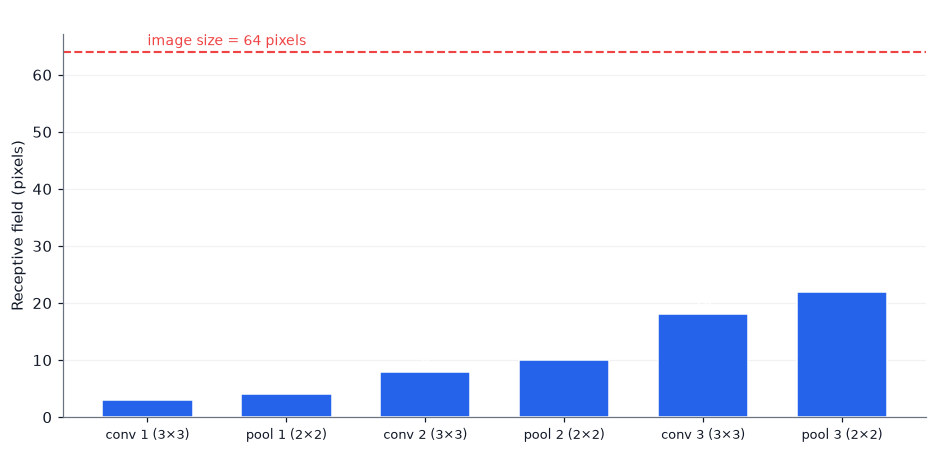


After three conv-pool blocks, each unit sees 22 of the 64 pixels per side; global average pooling then combines all positions.


In [20]:
def receptive_fields(layer_specs):
    r, j = 1, 1
    rows = []
    for name, k, s in layer_specs:
        r = r + (k - 1) * j
        j = j * s
        rows.append((name, r, j))
    return rows

specs = [("conv 1 (3\u00d73)", 3, 1), ("pool 1 (2\u00d72)", 2, 2), ("conv 2 (3\u00d73)", 3, 1), ("pool 2 (2\u00d72)", 2, 2), ("conv 3 (3\u00d73)", 3, 1), ("pool 3 (2\u00d72)", 2, 2)]
rf = receptive_fields(specs)
for name, r, j in rf:
    print(f"{name:18s} receptive field {r:>3} x {r:<3} pixels | jump {j}")

fig, ax = plt.subplots(figsize=(8.6, 4.2))
ax.bar([n for n, _, _ in rf], [r for _, r, _ in rf], color=COLORS["blue"], edgecolor="white", width=0.65)
ax.axhline(IMAGE_SIZE, color=COLORS["red"], linestyle="--", linewidth=1.4); ax.annotate(f"image size = {IMAGE_SIZE} pixels", (0, IMAGE_SIZE + 1.2), fontsize=9, color=COLORS["red"])
for i, (_, r, _) in enumerate(rf):
    ax.text(i, r + 0.8, str(r), ha="center", fontsize=9)
ax.set_ylabel("Receptive field (pixels)"); ax.set_title("Receptive field of the units after each layer"); ax.tick_params(axis="x", labelsize=8.5)
ax.grid(axis="x", visible=False)
finish(fig, "07_receptive_field")
print(f"\nAfter three conv-pool blocks, each unit sees {rf[-1][1]} of the {IMAGE_SIZE} pixels per side; global average pooling then combines all positions.")

# Part II — Building, training, and understanding CNNs

## 11. Designing the networks

We compare three models on the same data, splits, and training protocol:

| Model | Architecture |
|---|---|
| **MLP on pixels** | `Rescaling` → `Flatten` → `Dense(256, ReLU)` → `Dropout(0.3)` → `Dense(102, softmax)` |
| **CNN** | 3 blocks of [`Conv2D(3×3, "same")` → `ReLU` → `MaxPooling2D(2)`] with 32, 64, 128 filters → `GlobalAveragePooling2D` → `Dense(102, softmax)` |
| **CNN + BatchNorm + Dropout** | the same CNN with `BatchNormalization` after each convolution (Notebook 06) and `Dropout(0.3)` before the output layer |

**Design reasoning.**

- **Channels double while the spatial size halves** (32 → 64 → 128 filters; 64 → 32 → 16 → 8 pixels): early layers detect simple local patterns at high resolution; deeper layers combine them into more abstract features at lower resolution, so the cost of each block stays roughly constant.
- **3 × 3 kernels** are the standard small choice: two stacked $3\times3$ convolutions cover the same $5\times5$ receptive field as one $5\times5$ kernel with fewer parameters ($2\cdot 9 = 18$ against $25$ per channel pair) and an extra nonlinearity.
- **`"same"` padding** keeps the size constant inside a block, so that only the pooling layers change the resolution.
- **Global average pooling** instead of `Flatten` removes hundreds of thousands of parameters (Section 8).
- **No data augmentation in this notebook.** With only about 48 training images per class the networks will overfit; augmentation is the main topic of Notebook 09.

In [21]:
import pandas as pd

def build_mlp_images(size=IMAGE_SIZE, units=256, dropout=0.3, name="mlp_on_pixels"):
    return keras.Sequential([
        keras.layers.Input(shape=(size, size, 3), name="image"), keras.layers.Rescaling(1 / 255, name="rescale"),
        keras.layers.Flatten(name="flatten"), keras.layers.Dense(units, activation="relu", name="dense"),
        keras.layers.Dropout(dropout, name="dropout"), keras.layers.Dense(N_CLASSES, activation="softmax", name="class_probabilities"),
    ], name=name)

def build_cnn(size=IMAGE_SIZE, filters=(32, 64, 128), batch_norm=False, dropout=0.0, name="cnn"):
    layers = [keras.layers.Input(shape=(size, size, 3), name="image"), keras.layers.Rescaling(1 / 255, name="rescale")]
    for i, f in enumerate(filters, start=1):
        layers.append(keras.layers.Conv2D(f, 3, padding="same", use_bias=not batch_norm, name=f"conv_{i}"))
        if batch_norm:
            layers.append(keras.layers.BatchNormalization(name=f"bn_{i}"))
        layers.append(keras.layers.Activation("relu", name=f"relu_{i}"))
        layers.append(keras.layers.MaxPooling2D(2, name=f"pool_{i}"))
    layers.append(keras.layers.GlobalAveragePooling2D(name="gap"))
    if dropout > 0:
        layers.append(keras.layers.Dropout(dropout, name="dropout"))
    layers.append(keras.layers.Dense(N_CLASSES, activation="softmax", name="class_probabilities"))
    return keras.Sequential(layers, name=name)

def layer_table(model):
    """Output shape, parameters, and multiply-accumulate operations (MACs) of every layer."""
    rows = []
    for layer in model.layers:
        shape = tuple(layer.output.shape[1:])
        macs = 0
        if isinstance(layer, keras.layers.Conv2D):
            kh, kw, cin, cout = layer.kernel.shape
            macs = int(shape[0] * shape[1] * kh * kw * cin * cout)
        elif isinstance(layer, keras.layers.Dense):
            macs = int(np.prod(layer.kernel.shape))
        rows.append({"layer": layer.name, "type": type(layer).__name__, "output shape": str(shape), "parameters": layer.count_params(), "MACs": macs})
    return pd.DataFrame(rows)

cnn_preview = build_cnn()
table = layer_table(cnn_preview)
display(table)
print(f"Total parameters: {table['parameters'].sum():,} | total MACs per image: {table['MACs'].sum():,}")

# The formulas of Section 7 for the first two convolutions:
print("\nconv_1: (3*3*3 + 1) * 32 =", (3 * 3 * 3 + 1) * 32, "parameters | MACs = 64*64 * 3*3*3 * 32 =", 64 * 64 * 27 * 32)
print("conv_2: (3*3*32 + 1) * 64 =", (3 * 3 * 32 + 1) * 64, "parameters")
assert table.loc[table["layer"] == "conv_1", "parameters"].item() == (3 * 3 * 3 + 1) * 32
assert table.loc[table["layer"] == "conv_2", "parameters"].item() == (3 * 3 * 32 + 1) * 64
mlp_preview = build_mlp_images()
print(f"\nMLP on pixels: {mlp_preview.count_params():,} parameters (about {mlp_preview.count_params() / cnn_preview.count_params():.0f}x the CNN)")

,layer,type,output shape,parameters,MACs
0,rescale,Rescaling,"(64, 64, 3)",0,0
1,conv_1,Conv2D,"(64, 64, 32)",896,3538944
2,relu_1,Activation,"(64, 64, 32)",0,0
3,pool_1,MaxPooling2D,"(32, 32, 32)",0,0
4,conv_2,Conv2D,"(32, 32, 64)",18496,18874368
5,relu_2,Activation,"(32, 32, 64)",0,0
6,pool_2,MaxPooling2D,"(16, 16, 64)",0,0
7,conv_3,Conv2D,"(16, 16, 128)",73856,18874368
8,relu_3,Activation,"(16, 16, 128)",0,0
9,pool_3,MaxPooling2D,"(8, 8, 128)",0,0


Total parameters: 106,406 | total MACs per image: 41,300,736

conv_1: (3*3*3 + 1) * 32 = 896 parameters | MACs = 64*64 * 3*3*3 * 32 = 3538944
conv_2: (3*3*32 + 1) * 64 = 18496 parameters

MLP on pixels: 3,172,198 parameters (about 30x the CNN)


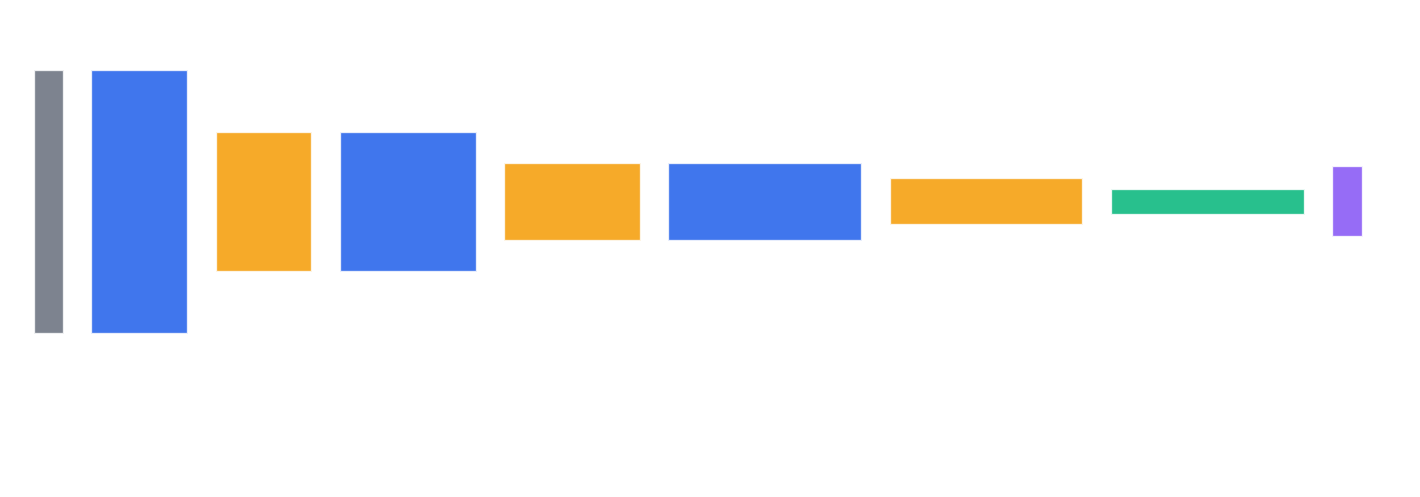

In [22]:
def draw_cnn_blocks(size=IMAGE_SIZE, filters=(32, 64, 128)):
    """Schematic of the CNN: box height ~ spatial size, box width ~ number of channels."""
    blocks = [("input", size, 3)]
    s = size
    for i, f in enumerate(filters, start=1):
        blocks.append((f"conv {i}\n+ ReLU", s, f)); s //= 2; blocks.append((f"pool {i}", s, f))
    fig, ax = plt.subplots(figsize=(13, 4.6))
    x = 0.0
    for name, spatial, channels in blocks:
        height, width = 0.06 * spatial + 0.25, 0.22 * math.sqrt(channels)
        color = COLORS["orange"] if name.startswith("pool") else (COLORS["gray"] if name == "input" else COLORS["blue"])
        ax.add_patch(plt.Rectangle((x, -height / 2), width, height, color=color, alpha=0.88, ec="white", lw=1.5))
        ax.text(x + width / 2, -2.6, f"{name}\n{spatial}\u00d7{spatial}\u00d7{channels}", ha="center", va="top", fontsize=8.5)
        x += width + 0.35
    ax.add_patch(plt.Rectangle((x, -0.2), 0.22 * math.sqrt(filters[-1]), 0.4, color=COLORS["green"], alpha=0.9, ec="white", lw=1.5))
    ax.text(x + 0.11 * math.sqrt(filters[-1]), -2.6, f"global avg\npool\n{filters[-1]}", ha="center", va="top", fontsize=8.5)
    x += 0.22 * math.sqrt(filters[-1]) + 0.35
    ax.add_patch(plt.Rectangle((x, -0.55), 0.4, 1.1, color=COLORS["purple"], alpha=0.9, ec="white", lw=1.5))
    ax.text(x + 0.2, -2.6, f"Dense +\nsoftmax\n{N_CLASSES}", ha="center", va="top", fontsize=8.5)
    ax.set_xlim(-0.3, x + 1.0); ax.set_ylim(-4.4, 2.6); ax.axis("off")
    ax.set_title("The CNN: resolution halves at each pooling, the number of feature maps doubles", loc="left")
    return fig

finish(draw_cnn_blocks(), "08_cnn_architecture")

## 12. Training and comparing the three models

All models use the Adam optimizer (learning rate $10^{-3}$), the **sparse categorical cross-entropy** (integer labels; with 102 classes, one-hot vectors would only waste memory — Notebook 04 explains that both are equivalent), batch size 64, early stopping on the validation loss (patience 8, best weights restored), and `ReduceLROnPlateau` (Notebook 06). We monitor **top-1** and **top-5 accuracy**:

$$
\text{top-}k\text{ accuracy} = \frac{1}{N}\sum_{i=1}^{N}\mathbf{1}\big\{y_i \in \text{the } k \text{ classes with the highest } \hat{p}_c(x_i)\big\} .
$$

Top-5 is informative for many-class problems with visually similar classes (a useful assistant for a botanist may return five candidates). Chance levels are $1/102 \approx 1.0\%$ and $5/102 \approx 4.9\%$.

In [23]:
def train_image_model(model, epochs, patience=8, batch_size=64, learning_rate=1e-3):
    model.compile(optimizer=keras.optimizers.Adam(learning_rate), loss="sparse_categorical_crossentropy",
                  metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy"),
                           keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top5_accuracy")])
    callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
                 keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5)]
    start = time.time()
    history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=epochs, batch_size=batch_size,
                        callbacks=callbacks, verbose=2)
    return history, time.time() - start

model_builders = {
    "MLP on pixels": (lambda: build_mlp_images(), epochs_for(40)),
    "CNN": (lambda: build_cnn(name="cnn"), epochs_for(40)),
    "CNN + BatchNorm + Dropout": (lambda: build_cnn(batch_norm=True, dropout=0.3, name="cnn_bn_dropout"), epochs_for(40)),
}
models, histories, train_seconds = {}, {}, {}
for name, (builder, n_epochs) in model_builders.items():
    print(f"\n===== {name} =====")
    keras.utils.set_random_seed(SEED)
    models[name] = builder()
    histories[name], train_seconds[name] = train_image_model(models[name], n_epochs)
    print(f"Training time: {train_seconds[name]:.0f} s")


===== MLP on pixels =====
Epoch 1/40
77/77 - 4s - 56ms/step - accuracy: 0.0343 - loss: 4.7543 - top5_accuracy: 0.1186 - val_accuracy: 0.0459 - val_loss: 4.4382 - val_top5_accuracy: 0.1831 - learning_rate: 0.0010
Epoch 2/40
77/77 - 3s - 40ms/step - accuracy: 0.0455 - loss: 4.4063 - top5_accuracy: 0.1812 - val_accuracy: 0.0600 - val_loss: 4.2475 - val_top5_accuracy: 0.2094 - learning_rate: 0.0010
Epoch 3/40
77/77 - 3s - 40ms/step - accuracy: 0.0542 - loss: 4.2813 - top5_accuracy: 0.1924 - val_accuracy: 0.0692 - val_loss: 4.1635 - val_top5_accuracy: 0.2290 - learning_rate: 0.0010
Epoch 4/40
77/77 - 3s - 43ms/step - accuracy: 0.0581 - loss: 4.1908 - top5_accuracy: 0.2037 - val_accuracy: 0.0845 - val_loss: 4.0641 - val_top5_accuracy: 0.2364 - learning_rate: 0.0010
Epoch 5/40
77/77 - 3s - 41ms/step - accuracy: 0.0656 - loss: 4.1304 - top5_accuracy: 0.2171 - val_accuracy: 0.0772 - val_loss: 3.9868 - val_top5_accuracy: 0.2596 - learning_rate: 0.0010
Epoch 6/40
77/77 - 3s - 40ms/step - accurac

,parameters,MACs per image,epochs run,best epoch,training time (s),train top-1,val top-1,val top-5,val loss
model,,,,,,,,,
MLP on pixels,"3,172,198","3,171,840",29,21,90,0.081,0.089,0.346,3.605
CNN,"106,406","41,300,736",40,40,307,0.570,0.473,0.773,2.121
CNN + BatchNorm + Dropout,"107,078","41,300,736",40,40,878,0.560,0.532,0.799,1.811


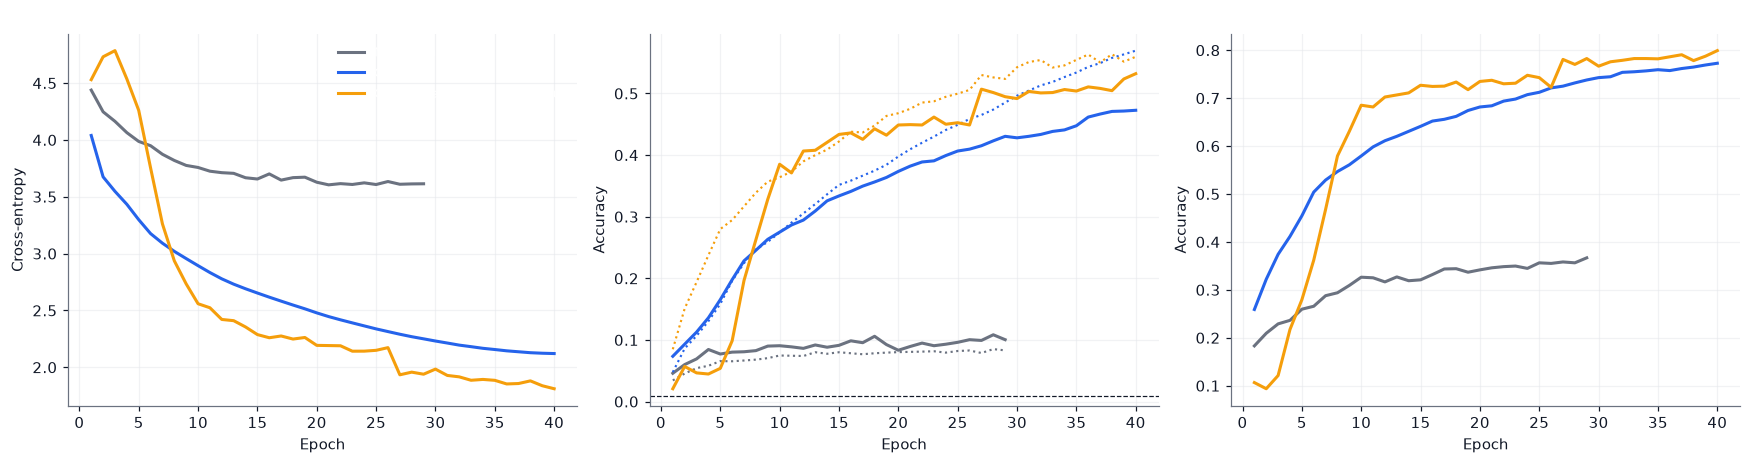

In [24]:
rows = []
for name, h in histories.items():
    hist = h.history; best = int(np.argmin(hist["val_loss"]))
    table_m = layer_table(models[name])
    rows.append({"model": name, "parameters": f"{models[name].count_params():,}", "MACs per image": f"{table_m['MACs'].sum():,}",
                 "epochs run": len(hist["loss"]), "best epoch": best + 1, "training time (s)": round(train_seconds[name]),
                 "train top-1": round(hist["accuracy"][best], 3), "val top-1": round(hist["val_accuracy"][best], 3),
                 "val top-5": round(hist["val_top5_accuracy"][best], 3), "val loss": round(hist["val_loss"][best], 3)})
comparison = pd.DataFrame(rows).set_index("model")
display(comparison)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for name, h in histories.items():
    hist, color = h.history, MODEL_COLORS[name]
    epochs_axis = np.arange(1, len(hist["loss"]) + 1)
    axes[0].plot(epochs_axis, hist["val_loss"], color=color, label=name)
    axes[1].plot(epochs_axis, hist["val_accuracy"], color=color, label=name)
    axes[1].plot(epochs_axis, hist["accuracy"], color=color, linestyle=":", linewidth=1.4)
    axes[2].plot(epochs_axis, hist["val_top5_accuracy"], color=color, label=name)
axes[0].set_title("Validation loss"); axes[1].set_title("Top-1 accuracy (solid: validation, dotted: training)"); axes[2].set_title("Validation top-5 accuracy")
for ax in axes:
    ax.set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy"); axes[1].set_ylabel("Accuracy"); axes[2].set_ylabel("Accuracy")
axes[1].axhline(1 / N_CLASSES, color=COLORS["dark"], linewidth=0.8, linestyle="--")
axes[0].legend(fontsize=8.5)
finish(fig, "09_model_comparison")

How to read the comparison (compare with your own table; absolute numbers depend on your hardware seed behaviour):

- **MLP versus CNN.** The MLP has far more parameters (about 3 million against a few tens of thousands for the CNN) but usually reaches a lower validation accuracy and overfits earlier: it must learn every pattern separately at every position and ignores the neighbourhood structure.
- **Training versus validation accuracy (dotted versus solid).** With 48 images per class, a large gap indicates overfitting. The version with BatchNorm and Dropout typically narrows the gap and often reaches a better validation accuracy, but it may also train more slowly per epoch.
- **Top-5 versus top-1.** Top-5 accuracy is much higher than top-1 for the same model: the true class is often among the first few candidates even when it is not the first one.
- All three numbers come from **one training run per model**. Differences of one or two percentage points are within the variation caused by random initialization (Notebook 06) and should not be over-interpreted.

### 12.1 Model selection

As in Notebook 07, we apply a rule **declared in advance**: *select the model with the highest validation top-1 accuracy.* Only after this decision do we look at the test set.

In [25]:
selected_name = comparison["val top-1"].astype(float).idxmax()
best_cnn_name = comparison.loc[[n for n in comparison.index if "CNN" in n], "val top-1"].astype(float).idxmax()
selected_model, best_cnn = models[selected_name], models[best_cnn_name]
print("Validation top-1 accuracy:", comparison["val top-1"].to_dict())
print("Selected model:", selected_name, "| best CNN (used in the inspection sections):", best_cnn_name)

Validation top-1 accuracy: {'MLP on pixels': 0.089, 'CNN': 0.473, 'CNN + BatchNorm + Dropout': 0.532}
Selected model: CNN + BatchNorm + Dropout | best CNN (used in the inspection sections): CNN + BatchNorm + Dropout


## 13. Looking inside the CNN

A trained network is not a black box if we know where to look.

### 13.1 Learned filters

The 32 filters of the first convolution are $3 \times 3 \times 3$ arrays — small enough to display as tiny colour images. Typically one finds edge-like and colour-blob detectors (compare with the hand-made Sobel filters of Section 7.5). With only 3×3 pixels and little training data, the filters of a small network are noisy and hard to interpret; larger networks trained on more data show cleaner structures.

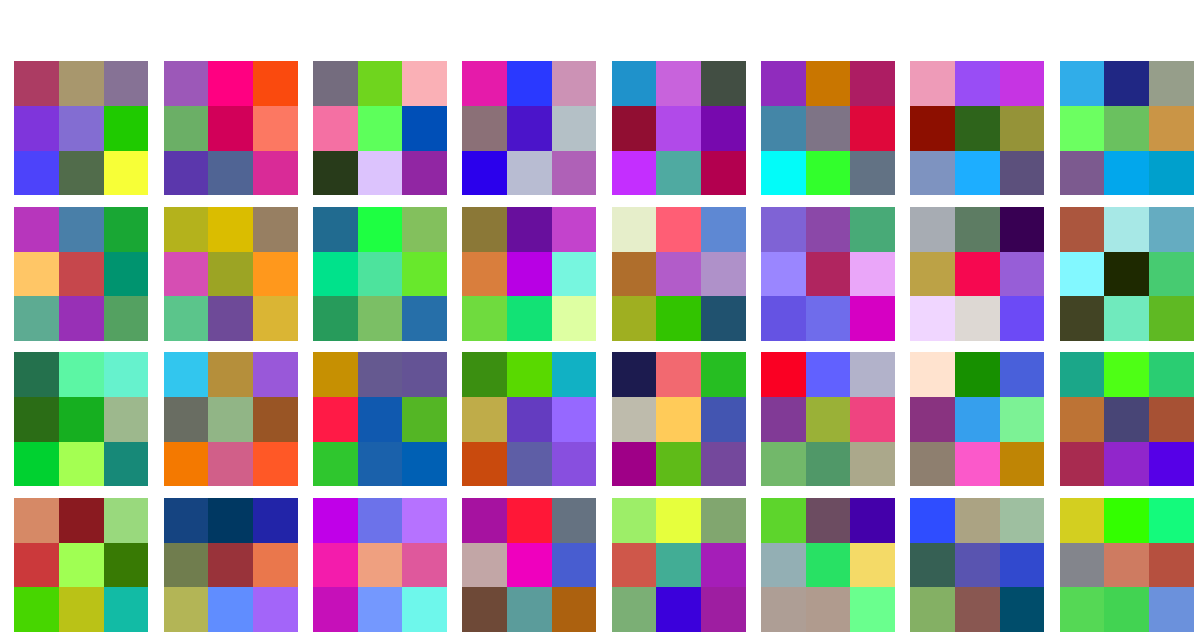

In [26]:
first_conv = next(layer for layer in best_cnn.layers if isinstance(layer, keras.layers.Conv2D))
kernels = first_conv.get_weights()[0]                                               # (3, 3, 3, 32)
n_filters = kernels.shape[-1]

fig, axes = plt.subplots(4, 8, figsize=(11, 5.8))
for f, ax in enumerate(axes.ravel()[:n_filters]):
    k = kernels[:, :, :, f]
    k = (k - k.min()) / (k.max() - k.min() + 1e-8)                                   # rescale each filter to [0, 1] for display
    ax.imshow(k, interpolation="nearest"); ax.axis("off")
for ax in axes.ravel()[n_filters:]:
    ax.axis("off")
fig.suptitle(f"The {n_filters} filters of the first convolution of '{best_cnn_name}' (3\u00d73 colour patches, each rescaled)", fontsize=12, fontweight="bold", x=0.01, ha="left", y=1.0)
finish(fig, "10_learned_filters")

### 13.2 Feature maps

We build a second model that returns the outputs of the three ReLU layers for the same input, so that we can see what each stage responds to. Early maps look like filtered versions of the photograph (edges, colours); deeper maps are smaller and more abstract, and respond to larger structures.

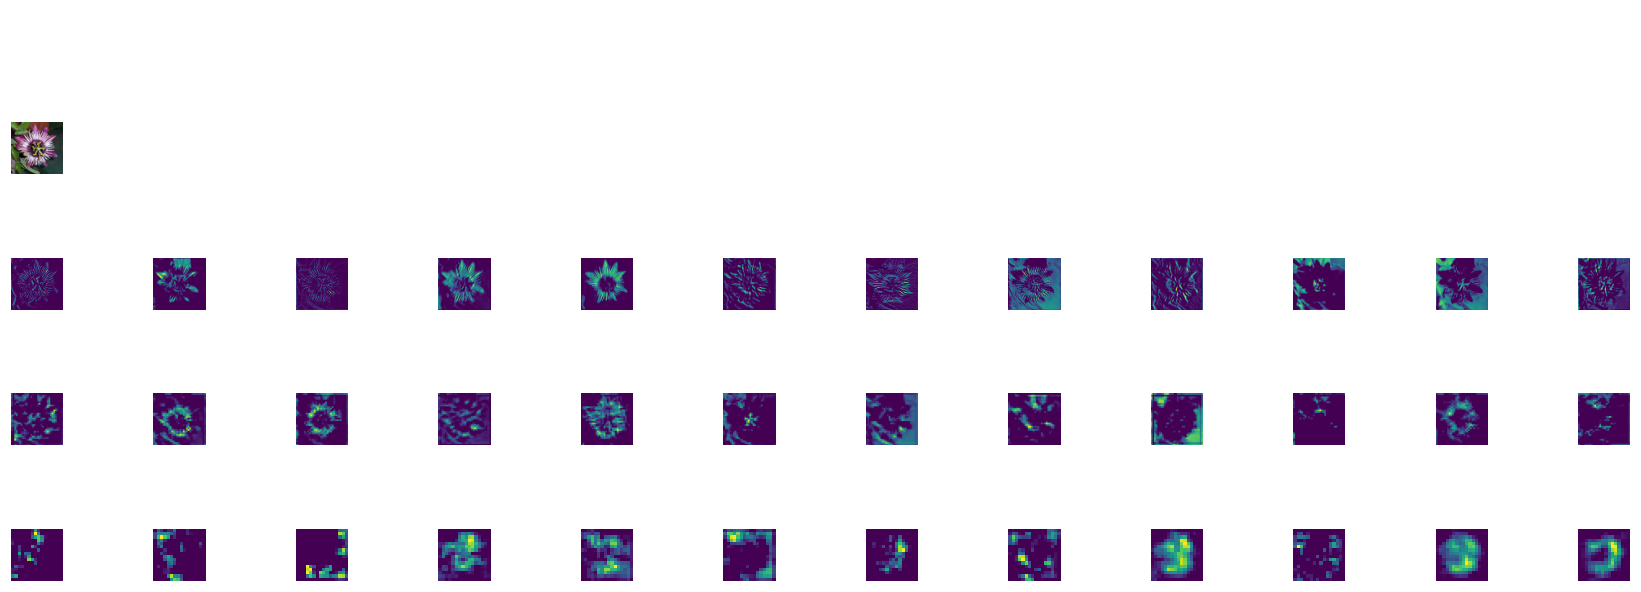

In [27]:
feature_layers = [best_cnn.get_layer(f"relu_{i}") for i in (1, 2, 3)]
feature_model = keras.Model(inputs=best_cnn.inputs, outputs=[layer.output for layer in feature_layers])

example_index = int(np.flatnonzero(y_val == y_val[0])[0])
example_image = X_val[example_index]
maps = [keras.ops.convert_to_numpy(m)[0] for m in feature_model.predict(example_image[None], verbose=0)]

n_show = 12
fig, axes = plt.subplots(4, n_show, figsize=(15, 5.6))
for ax in axes[0]:
    ax.axis("off")
axes[0, 0].imshow(example_image); axes[0, 0].set_title(f"input\nclass {y_val[example_index]}", fontsize=9)
for row, (fmap, layer) in enumerate(zip(maps, feature_layers), start=1):
    for c in range(n_show):
        axes[row, c].imshow(fmap[:, :, c], cmap="viridis"); axes[row, c].axis("off")
    axes[row, 0].set_title(f"{layer.name}: {fmap.shape[0]}\u00d7{fmap.shape[1]}, {fmap.shape[2]} maps (first {n_show} shown)", fontsize=9, loc="left")
fig.suptitle("Feature maps of one image at three depths", fontsize=12, fontweight="bold", x=0.01, ha="left", y=1.0)
finish(fig, "11_feature_maps")

### 13.3 Occlusion sensitivity: where does the model look?

A simple, **model-agnostic** way to ask which parts of an image the network uses: slide a grey square over the image and record how the predicted probability of the **true class** drops. A large drop means that the covered region was important for that prediction. Formally, for a patch at position $(i, j)$,

$$
\text{importance}(i, j) = \hat{p}_c(x) - \hat{p}_c\big(x \text{ with the patch at } (i,j) \text{ replaced by its mean colour}\big) .
$$

No gradients are needed, only repeated predictions. The map is only as good as the question it asks: occluding a region also creates an artificial edge, and the network may react to that, so occlusion maps are *indications*, not proofs, of what the network relies on. A model can also be right for the wrong reason: if the map highlights the **background** (grass, a pot, a label) instead of the flower, the model may be using context that would not generalize.

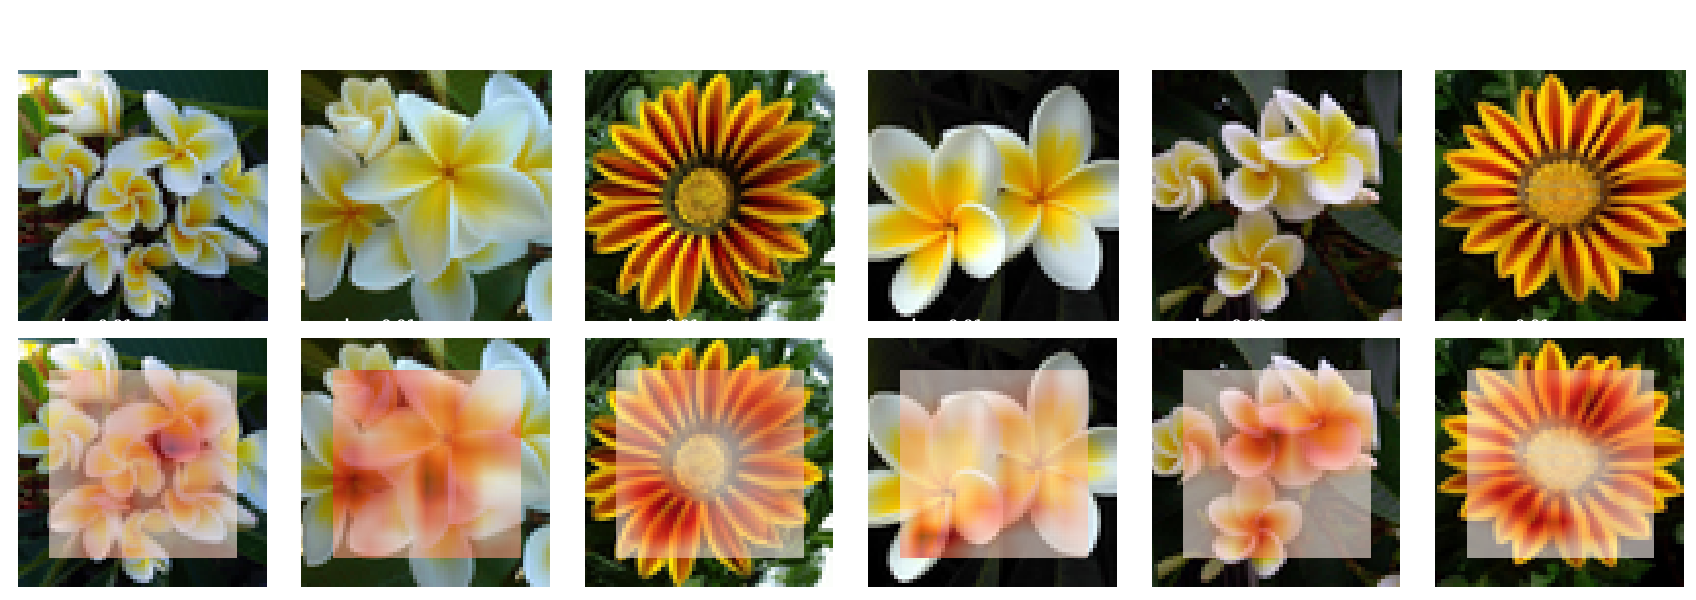

In [28]:
def occlusion_map(model, image, true_class, patch=16, stride=4):
    S = image.shape[0]
    positions = list(range(0, S - patch + 1, stride))
    fill = image.mean(axis=(0, 1)).astype(np.uint8)
    batch = []
    for i in positions:
        for j in positions:
            occluded = image.copy(); occluded[i:i + patch, j:j + patch, :] = fill
            batch.append(occluded)
    probs = model.predict(np.stack(batch), verbose=0)[:, true_class]
    base = float(model.predict(image[None], verbose=0)[0, true_class])
    return base, (base - probs).reshape(len(positions), len(positions)), positions

probs_val = best_cnn.predict(X_val, verbose=0)
correct_idx = np.flatnonzero(probs_val.argmax(1) == y_val)
chosen = correct_idx[np.argsort(-probs_val[correct_idx, y_val[correct_idx]])][:6]            # confident, correct examples

PATCH = 16
fig, axes = plt.subplots(2, len(chosen), figsize=(2.6 * len(chosen), 5.4))
for col, i in enumerate(chosen):
    base, drop, positions = occlusion_map(best_cnn, X_val[i], int(y_val[i]), patch=PATCH)
    axes[0, col].imshow(X_val[i]); axes[0, col].set_title(f"class {y_val[i]}, p = {base:.2f}", fontsize=9); axes[0, col].axis("off")
    c0, c1 = positions[0] + PATCH / 2, positions[-1] + PATCH / 2
    axes[1, col].imshow(X_val[i]); axes[1, col].axis("off")
    im = axes[1, col].imshow(drop, cmap="Reds", alpha=0.6, extent=(c0, c1, c1, c0), interpolation="bilinear", vmin=0)
    axes[1, col].set_xlim(0, IMAGE_SIZE); axes[1, col].set_ylim(IMAGE_SIZE, 0)
    axes[1, col].set_title(f"max drop {drop.max():.2f}", fontsize=9)
fig.suptitle("Occlusion sensitivity (red: covering this region lowers the probability of the true class)", fontsize=12, fontweight="bold", x=0.01, ha="left", y=1.0)
finish(fig, "12_occlusion_maps")

## 14. Final evaluation on the test set

The test set is used **once**, for the model selected on the validation set. We report

- **top-1 and top-5 accuracy** with 95% **Wilson intervals** (Notebook 07): with about 1,640 test images the interval for an accuracy around 50% is roughly $\pm 2.4$ percentage points;
- **per-class accuracy** with its interval. Each class has only about 16 test images (some 8, some 50), so per-class numbers are very uncertain: an observed accuracy of 12/16 has a Wilson interval of about 51%–90%;
- the **confusion structure**: which pairs of classes are mixed up.

In [29]:
def wilson_interval(k, n, z=1.959964):
    if n == 0:
        return 0.0, 1.0
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return max(0.0, centre - half), min(1.0, centre + half)

def topk_correct(probs, y, k):
    top = np.argpartition(-probs, k - 1, axis=1)[:, :k]
    return (top == y[:, None]).any(axis=1)

probs_test = selected_model.predict(X_test, verbose=0)
pred_test = probs_test.argmax(axis=1)
top1 = pred_test == y_test
top5 = topk_correct(probs_test, y_test, 5)
n_test = len(y_test)

print(f"Selected model: {selected_name}")
for label, correct in [("Top-1 accuracy", top1), ("Top-5 accuracy", top5)]:
    lo, hi = wilson_interval(int(correct.sum()), n_test)
    print(f"  {label}: {correct.mean():.3f}   95% Wilson interval [{lo:.3f}, {hi:.3f}]   ({int(correct.sum())} of {n_test})")
print(f"  Chance level: top-1 {1 / N_CLASSES:.3f}, top-5 {5 / N_CLASSES:.3f}")

# The validation estimate of the same model, for comparison (it was used for model selection, so it is slightly optimistic):
val_probs = selected_model.predict(X_val, verbose=0)
print(f"\nValidation top-1 of the selected model: {np.mean(val_probs.argmax(1) == y_val):.3f}  (test: {top1.mean():.3f})")

Selected model: CNN + BatchNorm + Dropout
  Top-1 accuracy: 0.535   95% Wilson interval [0.510, 0.559]   (873 of 1633)
  Top-5 accuracy: 0.796   95% Wilson interval [0.776, 0.815]   (1300 of 1633)
  Chance level: top-1 0.010, top-5 0.049

Validation top-1 of the selected model: 0.532  (test: 0.535)


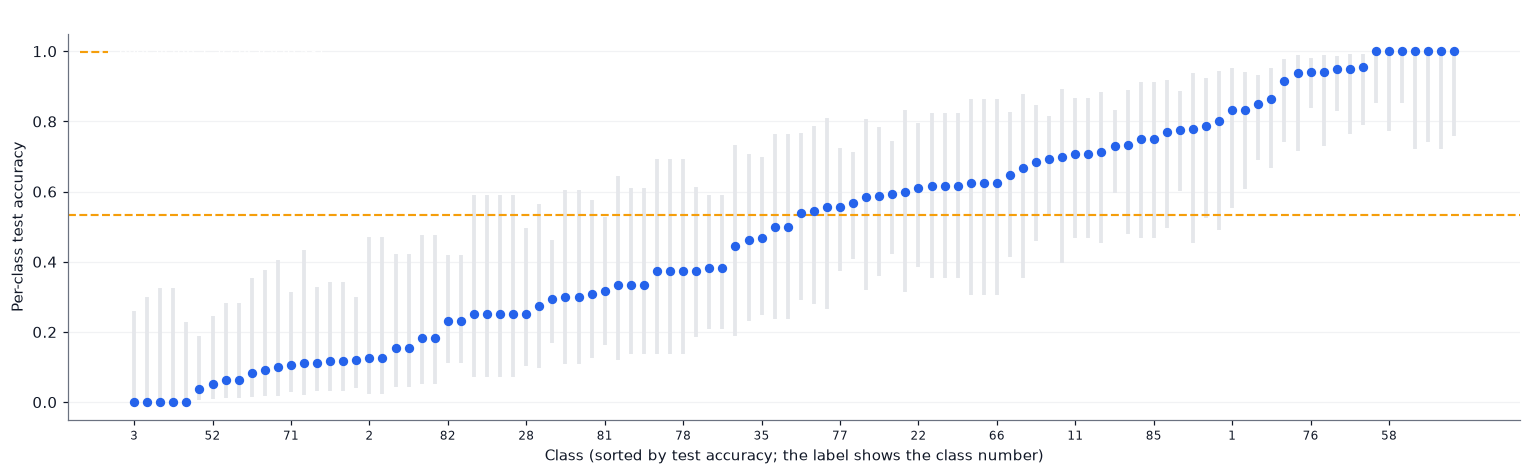

Classes with 0% accuracy: 5 | classes with 100% accuracy: 7
The five classes with the lowest accuracy (class: correct/total): {3: '0/11', 31: '0/9', 33: '0/8', 38: '0/8', 39: '0/13'}


In [30]:
per_class_n = np.bincount(y_test, minlength=N_CLASSES)
per_class_k = np.bincount(y_test[top1], minlength=N_CLASSES)
per_class_acc = per_class_k / per_class_n
intervals = np.array([wilson_interval(int(k), int(n)) for k, n in zip(per_class_k, per_class_n)])

order = np.argsort(per_class_acc, kind="stable")
fig, ax = plt.subplots(figsize=(14, 4.4))
x_pos = np.arange(N_CLASSES)
ax.vlines(x_pos, intervals[order, 0], intervals[order, 1], color=COLORS["light"], linewidth=2.5, zorder=1)
ax.scatter(x_pos, per_class_acc[order], s=26, color=COLORS["blue"], zorder=3)
ax.axhline(top1.mean(), color=COLORS["orange"], linestyle="--", linewidth=1.4, label=f"overall top-1 accuracy ({top1.mean():.2f})")
ax.set_xticks(x_pos[::6]); ax.set_xticklabels([f"{c}" for c in order[::6]], fontsize=8)
ax.set_xlabel("Class (sorted by test accuracy; the label shows the class number)"); ax.set_ylabel("Per-class test accuracy")
ax.set_title("Per-class accuracy with 95% Wilson intervals (about 16 test images per class: wide intervals)")
ax.legend(loc="upper left"); ax.grid(axis="x", visible=False)
finish(fig, "13_per_class_accuracy")
print("Classes with 0% accuracy:", int(np.sum(per_class_k == 0)), "| classes with 100% accuracy:", int(np.sum(per_class_k == per_class_n)))
print("The five classes with the lowest accuracy (class: correct/total):", {int(c): f"{per_class_k[c]}/{per_class_n[c]}" for c in order[:5]})

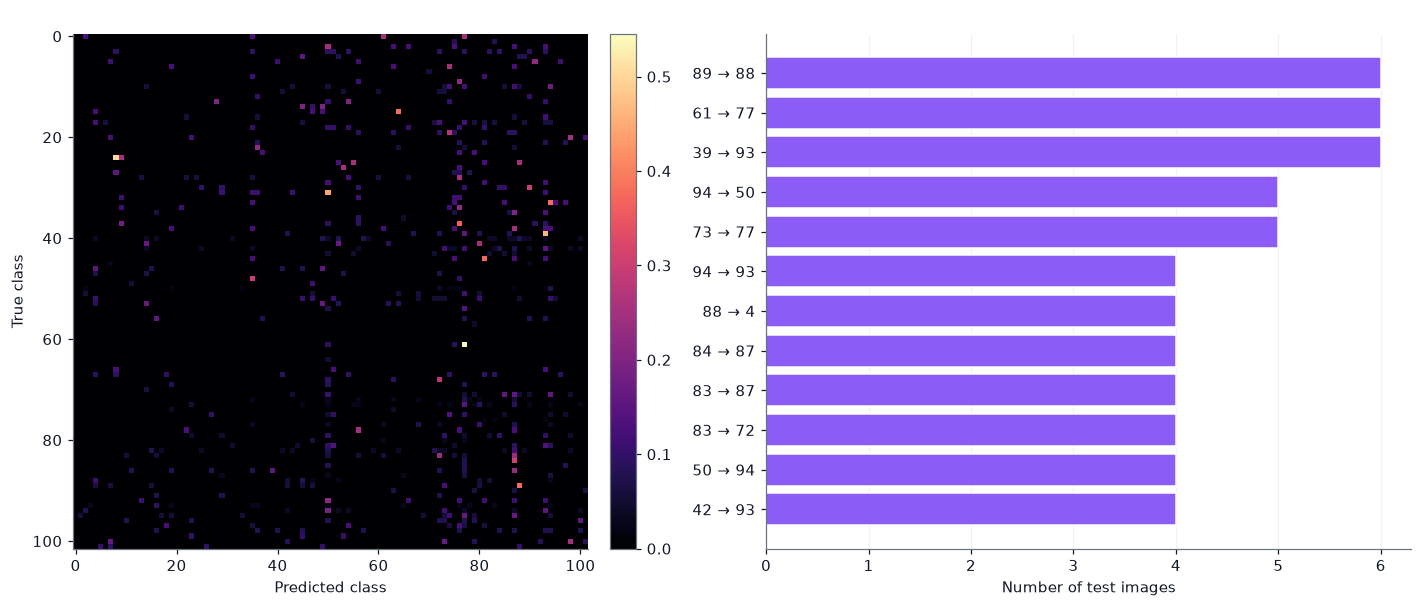

In [31]:
cm = np.zeros((N_CLASSES, N_CLASSES), dtype=int)
np.add.at(cm, (y_test, pred_test), 1)
row_norm = cm / cm.sum(axis=1, keepdims=True)
off_diag = row_norm.copy(); np.fill_diagonal(off_diag, 0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw={"width_ratios": [1.15, 1]})
im = axes[0].imshow(off_diag, cmap="magma", vmin=0, vmax=max(off_diag.max(), 1e-6))
axes[0].grid(False); axes[0].set_xlabel("Predicted class"); axes[0].set_ylabel("True class")
axes[0].set_title("Confusions only (correct predictions removed), fraction of the true class")
fig.colorbar(im, ax=axes[0], fraction=0.046, pad=0.03)

pairs = [(cm[i, j], i, j) for i in range(N_CLASSES) for j in range(N_CLASSES) if i != j and cm[i, j] > 0]
pairs.sort(reverse=True)
top_pairs = pairs[:12]
labels_pairs = [f"{i} \u2192 {j}" for _, i, j in top_pairs][::-1]
axes[1].barh(range(len(top_pairs)), [c for c, _, _ in top_pairs][::-1], color=COLORS["purple"], edgecolor="white")
axes[1].set_yticks(range(len(top_pairs))); axes[1].set_yticklabels(labels_pairs); axes[1].set_xlabel("Number of test images")
axes[1].set_title("Most frequent confusions (true \u2192 predicted)"); axes[1].grid(axis="y", visible=False)
finish(fig, "14_confusions")

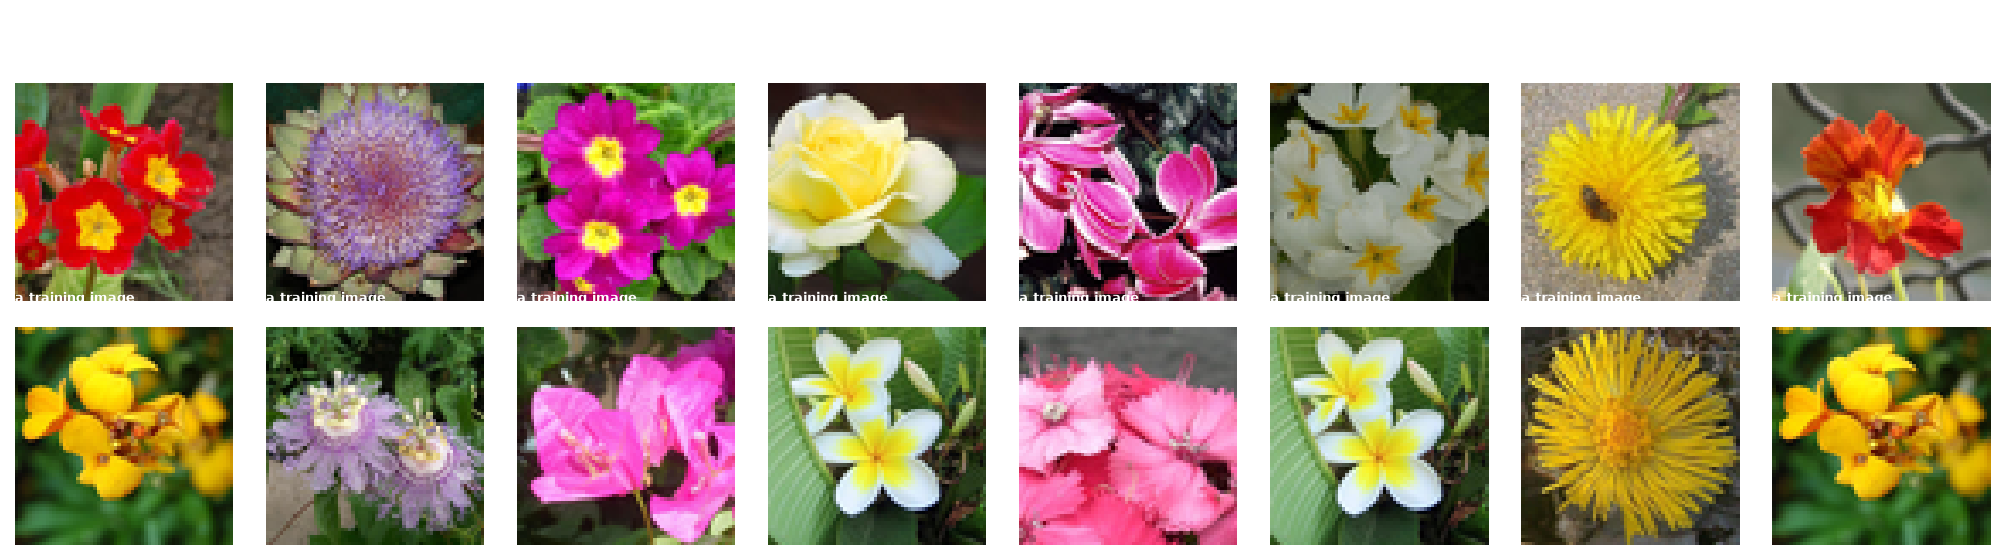

Misclassified test images: 760 of 1633


In [32]:
# The most confident mistakes, next to a training image of the class the model predicted.
wrong = np.flatnonzero(~top1)
confidence = probs_test[wrong, pred_test[wrong]]
worst = wrong[np.argsort(-confidence)][:8]

fig, axes = plt.subplots(2, len(worst), figsize=(2.3 * len(worst), 5.0))
for col, i in enumerate(worst):
    axes[0, col].imshow(X_test[i]); axes[0, col].axis("off")
    axes[0, col].set_title(f"true {y_test[i]} \u2192 pred {pred_test[i]}\nconfidence {probs_test[i, pred_test[i]]:.2f}", fontsize=8.5)
    train_example = X_train[np.flatnonzero(y_train == pred_test[i])[0]]
    axes[1, col].imshow(train_example); axes[1, col].axis("off")
    axes[1, col].set_title(f"a training image\nof class {pred_test[i]}", fontsize=8.5)
fig.suptitle(f"The {len(worst)} most confident mistakes (top row) and an example of the class that was predicted (bottom row)", fontsize=12, fontweight="bold", x=0.01, ha="left", y=1.0)
finish(fig, "15_confident_errors")
print("Misclassified test images:", len(wrong), "of", n_test)

The confusion structure usually shows **pairs of visually similar species** (similar colour and shape) rather than random mistakes; the bottom row of the last figure lets you judge whether a human would also hesitate. Some errors are probably label-ambiguous or caused by the preprocessing (the centre crop can remove the characteristic part of an elongated flower).

## 15. Scientific interpretation and limitations

**What the results can support.** A small CNN, trained from scratch on a few thousand low-resolution photographs, learns visual cues for flower species far beyond chance, and a convolutional architecture is a much better inductive bias than a fully connected one for images (fewer parameters, better accuracy).

**What the results do not support.**

1. *Small images and no augmentation.* At 64 × 64 pixels much fine detail (petal texture, venation) is lost, and with about 48 images per class the networks overfit. Both limitations are addressed in Notebook 09.
2. *Near-duplicate images.* Photographs of the same plant may appear in the training and test partitions (Section 4.1), so test accuracy may be optimistic; the dataset gives no plant identifier for a grouped split.
3. *Dataset scope.* The images show 102 species common in the UK, photographed in the field under varied conditions. The classifier cannot recognize species outside these classes (it will still output one of the 102 labels, with a confidence that is not a reliable sign of being *in* the set), and it may not transfer to other regions, herbarium sheets, or a different camera.
4. *Occlusion maps and filters are qualitative.* They suggest hypotheses about what the network uses; they do not prove it.
5. *One run per model.* We did not repeat the training with several seeds, so small differences between models are not significant (Notebooks 06 and 07).
6. *Biology beyond flowers.* The same architecture and the same evaluation habits apply to microscopy (cell types, histology patches), plant phenotyping, wildlife camera traps, and similar tasks. In each case the scientific questions are the same: is the split free of leakage, is the class balance realistic, and does the model look at the biology or at an artefact (stain, scale bar, background)?

## 16. Saving the model with its metadata

In [33]:
model_path = os.path.join(ARTIFACT_DIR, "flowers102_cnn.keras")
selected_model.save(model_path)

lo1, hi1 = wilson_interval(int(top1.sum()), n_test); lo5, hi5 = wilson_interval(int(top5.sum()), n_test)
metadata = {
    "dataset": "Oxford 102 Flowers (Nilsback and Zisserman, 2008)",
    "image_size": IMAGE_SIZE, "n_classes": N_CLASSES, "preprocessing": "resize shorter side then centre crop; Rescaling(1/255) inside the model",
    "split": {"kind": "own stratified split of all images", "seed": SEED, "train": int(len(y_train)), "validation": int(len(y_val)), "test": int(len(y_test))},
    "selected_model": selected_name, "selection_rule": "highest validation top-1 accuracy",
    "validation_top1": {k: float(v) for k, v in comparison["val top-1"].items()},
    "test_top1": float(top1.mean()), "test_top1_95ci_wilson": [lo1, hi1],
    "test_top5": float(top5.mean()), "test_top5_95ci_wilson": [lo5, hi5],
    "versions": {"python": sys.version.split()[0], "keras": keras.__version__, "backend": keras.backend.backend(), "numpy": np.__version__},
}
with open(os.path.join(ARTIFACT_DIR, "flowers102_metadata.json"), "w") as f:
    json.dump(metadata, f, indent=2)

reloaded = keras.models.load_model(model_path)
print("Reloaded predictions identical:", np.allclose(reloaded.predict(X_test[:16], verbose=0), probs_test[:16], atol=1e-4))

# Using the model: a raw uint8 image goes in (Rescaling is part of the model); five candidate classes come out.
probs_one = reloaded.predict(X_test[:1], verbose=0)[0]
top_candidates = np.argsort(-probs_one)[:5]
print("\nTop-5 candidate classes for one test image (true class", int(y_test[0]), "):", {int(c): round(float(probs_one[c]), 3) for c in top_candidates})

Reloaded predictions identical: True

Top-5 candidate classes for one test image (true class 17 ): {93: 0.163, 39: 0.137, 71: 0.111, 17: 0.083, 86: 0.053}


## 17. What did we learn?

1. An image is a tensor $(H, W, C)$; a batch is $(N, H, W, C)$. Rescaling belongs **inside** the model.
2. A Dense layer on pixels needs $(3S^2+1)U$ parameters and ignores neighbourhoods; a convolution has $(k_hk_wC_{in}+1)C_{out}$ parameters **independent of the image size**, through local connectivity and parameter sharing.
3. The convolution computes $Y_{i,j,f} = b_f + \sum_{m,n,c}\tilde{X}_{si+m,\,sj+n,\,c}K_{m,n,c,f}$; its output size is $\lfloor (n+2p-k)/s \rfloor + 1$ (`"same"`: $\lceil n/s \rceil$, extra zero padding after the image), and it costs $H_{out}W_{out}k_hk_wC_{in}C_{out}$ MACs. Our NumPy implementation agrees with Keras.
4. Convolution is **translation-equivariant**; max pooling adds local invariance and enlarges the receptive field; **global average pooling** removes most of the parameters of the classifier head.
5. The gradients of a convolution are a **correlation of the input with the upstream gradient** (kernel) and a **full convolution with the kernel** (input); a numerical gradient check confirms them. Max pooling routes the gradient to the argmax.
6. The **receptive field** grows as $r_l = r_{l-1} + (k_l-1)j_{l-1}$; a unit can only recognize patterns that fit inside it.
7. On 102 flower classes, a small CNN outperforms a much larger MLP; BatchNorm and Dropout help against overfitting with ~48 images per class.
8. Filters, feature maps, and **occlusion sensitivity** let us inspect what the network uses; they are indications, not proofs.
9. Evaluation of a many-class image classifier: top-1 and top-5 accuracy with intervals, per-class accuracy with wide intervals, the confusion structure, and an inspection of the most confident errors — and an honest statement of leakage and scope limitations.

### Key terms

| Term | Meaning |
|---|---|
| Channels-last | Image tensors with shape $(N, H, W, C)$ |
| Cross-correlation / convolution | Sliding weighted sum with a small kernel, shared across positions |
| Kernel / filter / feature map | The weight array / one learned detector / its output over all positions |
| Stride, padding | Step of the sliding window / zeros added around the input |
| `"valid"`, `"same"` | No padding / padding that gives $\lceil n/s \rceil$ outputs |
| MACs | Multiply–accumulate operations (a measure of computational cost) |
| Equivariance, invariance | Output shifts with the input / output is unchanged by a shift |
| Max / average / global average pooling | Window maximum / window mean / mean of the whole feature map |
| Receptive field | Region of the input that can influence a unit |
| Top-$k$ accuracy | The true class is among the $k$ most probable predictions |
| Occlusion sensitivity | Drop in the predicted probability when a region is hidden |

## 18. Exercises

### A. Mathematics

1. For an input of $n = 100$, a kernel $k = 5$, stride $s = 2$, and padding $p = 2$, compute the output size. Repeat for `"valid"` and `"same"` padding in Keras.
2. A convolution layer has input $32 \times 32 \times 16$, 64 filters of size $3 \times 3$, stride 1, `"same"` padding. Compute the number of parameters, the output shape, and the number of MACs. How do these change if the input becomes $64 \times 64 \times 16$?
3. Show that two stacked $3 \times 3$ convolutions have a $5 \times 5$ receptive field, and compare their number of parameters with one $5 \times 5$ convolution, for $C$ input and $C$ output channels. Repeat for three stacked $3 \times 3$ against one $7 \times 7$.
4. A **$1 \times 1$ convolution** has kernel size 1. Show that it is a Dense layer applied independently at every pixel, and compute its parameter count for $C_{in}$ input and $C_{out}$ output channels.
5. A **depthwise separable convolution** applies one $k \times k$ filter per input channel and then a $1 \times 1$ convolution. Compare the number of parameters with a standard convolution, for $k = 3$, $C_{in} = 64$, $C_{out} = 128$.
6. Prove translation equivariance for stride $s > 1$: for which shifts does $\operatorname{conv}(T_\Delta X) = T_{\Delta/s}\operatorname{conv}(X)$ hold?
7. Derive the gradient of **global average pooling** and of **max pooling** with respect to their inputs.
8. Derive $\partial L / \partial X_{p,q,c}$ for a convolution with stride 2 (hint: the output positions that touch input position $(p, q)$ are fewer).
9. Compute the receptive field of the CNN of this notebook if every block had **two** $3 \times 3$ convolutions before the pooling layer.

### B. Programming

1. Implement the convolution with **im2col**: unfold every window into a row of a matrix and perform a single matrix product. Compare its speed with `conv2d_numpy`.
2. Replace `GlobalAveragePooling2D` by `Flatten` and compare the number of parameters, the training time, and the validation accuracy.
3. Change the filters to `(16, 32, 64)` and `(64, 128, 256)`. Plot validation accuracy against the number of parameters.
4. Add a fourth convolution–pooling block. How does the receptive field and the accuracy change?
5. Use `IMAGE_SIZE = 96` or `128`. How much does the accuracy improve and how much does the training time increase?
6. Use the **official** split (`trnid`, `valid`, `tstid`) instead of the stratified split. How do the three models behave with only about 10 images per class?
7. Replace each max-pooling layer with a convolution of stride 2 ("strided convolution"). Compare accuracy and parameters.
8. Implement **Grad-CAM** (gradient-weighted class activation mapping) with `tf.GradientTape` and compare it with the occlusion maps.
9. Train the best CNN with three different seeds and report the mean and standard deviation of the validation accuracy. Is the difference between the CNN and the CNN + BatchNorm + Dropout larger than the seed-to-seed variation?

### C. Research thinking

1. A botanist wants to use the model on herbarium specimens (pressed, dried plants on white paper). Which assumptions of this notebook break, and how would you evaluate whether the model still works?
2. The occlusion map of a correctly classified image highlights the green background rather than the flower. What does this suggest, and how would you test whether the model uses the background?
3. You want to classify cell types in microscopy images of a tissue section from 12 patients. Describe a train/validation/test protocol that avoids leakage (hint: Notebook 07, grouped splits), and which metrics you would report.
4. Why is the confidence of a softmax classifier a poor indicator that an image belongs to *none* of the 102 species? What would you add to the system to handle unknown species?

## 19. Further exploration and references

### Dataset

- Nilsback, M.-E. and Zisserman, A. (2008). Automated flower classification over a large number of classes. *Indian Conference on Computer Vision, Graphics and Image Processing*. Dataset page: <https://www.robots.ox.ac.uk/~vgg/data/flowers/102/>. Check the page for the terms of use of the images before redistributing any of them.

### Methods

- LeCun, Y., Bottou, L., Bengio, Y., and Haffner, P. (1998). Gradient-based learning applied to document recognition. *Proceedings of the IEEE*, 86(11), 2278–2324.
- Krizhevsky, A., Sutskever, I., and Hinton, G. (2012). ImageNet classification with deep convolutional neural networks. *NeurIPS*.
- Simonyan, K. and Zisserman, A. (2015). Very deep convolutional networks for large-scale image recognition. *ICLR*.
- He, K., Zhang, X., Ren, S., and Sun, J. (2016). Deep residual learning for image recognition. *CVPR*.
- Lin, M., Chen, Q., and Yan, S. (2014). Network in network (global average pooling, $1 \times 1$ convolutions). *ICLR*.
- Zeiler, M. D. and Fergus, R. (2014). Visualizing and understanding convolutional networks. *ECCV*.
- Selvaraju, R. R., *et al.* (2017). Grad-CAM: visual explanations from deep networks via gradient-based localization. *ICCV*.
- Dumoulin, V. and Visin, F. (2016). A guide to convolution arithmetic for deep learning. arXiv:1603.07285.
- Luo, W., Li, Y., Urtasun, R., and Zemel, R. (2016). Understanding the effective receptive field in deep convolutional neural networks. *NeurIPS*.

### Keras documentation

- [Convolution layers](https://keras.io/api/layers/convolution_layers/) and [pooling layers](https://keras.io/api/layers/pooling_layers/)
- [`Rescaling`](https://keras.io/api/layers/preprocessing_layers/image_preprocessing/rescaling/) and [metrics](https://keras.io/api/metrics/) (`SparseTopKCategoricalAccuracy`)
- Keras example guides on image classification from scratch.

### Suggested reading

- Goodfellow, Bengio, and Courville — *Deep Learning*: chapter 9 (convolutional networks).
- Chollet — *Deep Learning with Python*: the chapters on convnets and on interpreting what convnets learn.
- Géron — *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow*: the chapter on deep computer vision with CNNs.

---

## Next notebook

**09 — Transfer Learning and Data Augmentation**

We keep the Flowers dataset and attack the two limitations of this notebook: too few images per class and too little visual detail. We use **data augmentation** to enlarge the effective training set, and **transfer learning** — a network pretrained on ImageNet used as a feature extractor, then fine-tuned — and compare it with the CNN trained from scratch, with careful attention to the evaluation protocol.